In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [8]:
n0    = 0.15
n_b = [0.165, 0.32, 0.5344, 0.7500, 2]
K_b = [17906.60, 63.177, 774.375, 548.309 ]
Gam_b = [4.921, 0, 4.00,2.80]
m0 = [939.56, 1201.75, 1031.815, 958.55]

#K_b = [2.1680,63.178,0.5075,3.2401]
#n_b = np.array(n_b/n0)

In [3]:
n0    = 0.15
n_b = [0.165, 0.32, 0.5344, 1]
K_b = [17906.60, 63.177, 548.309 ]
Gam_b = [4.921, 0, 4]
m0 = [939.56, 1201.75, 958.55]

#K_b = [2.1680,63.178,0.5075,3.2401]
#n_b = np.array(n_b/n0)

In [4]:
@jit(nopython=True)
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

@jit(nopython=True)
def cs(mu,K,Gam,n_list):
    t1 = 1/mu
    t2 = K*Gam*((n_list)**(Gam-1))
    t = t1*t2
    return t

In [5]:
(-P1_b[-1]+74.402)/P1_b[-1]

NameError: name 'P1_b' is not defined

In [9]:
n1_b = np.linspace(n_b[0], n_b[1], 20)
P1_b = P_from_nb(n1_b, K_b[0], Gam_b[0])
mu1_b = mu_from_nb(n1_b, K_b[0], Gam_b[0], m0[0])
e1_b = e_from_n(n1_b, K_b[0], Gam_b[0], m0[0])
#cs_1 = cs(mu1_b,K_b[0],Gam_b[0],n_b[0])

n2_b = np.linspace(n_b[1], n_b[2], 20)
P2_b = P_from_nb(n2_b, K_b[1], Gam_b[1])
mu2_b = mu_from_nb(n2_b, K_b[1], Gam_b[1], m0[1])
e2_b = e_from_n(n2_b, K_b[1], Gam_b[1], m0[1])
#cs_2 = cs(mu2_b,K_b[1],Gam_b[1],n_b[1])

n3_b = np.linspace(n_b[2], n_b[3], 20)
P3_b = P_from_nb(n3_b, K_b[2], Gam_b[2])
mu3_b = mu_from_nb(n3_b, K_b[2], Gam_b[2], m0[2])
e3_b = e_from_n(n3_b, K_b[2], Gam_b[2], m0[2])
#cs_3 = cs(mu3_b,K_b[2],Gam_b[2],n_b[2])


P_arr = np.concatenate((P1_b[1:-1], P2_b[1:-1], P3_b[1:-1]))
e_arr = np.concatenate((e1_b[1:-1], e2_b[1:-1], e3_b[1:-1]))
n_arr = np.concatenate((n1_b[1:-1], n2_b[1:-1], n3_b[1:-1]))
mu_arr = np.concatenate((mu1_b[1:-1], mu2_b[1:-1], mu3_b[1:-1]))
#cs_arr = np.concatenate((cs_1,cs_2,cs_3,cs_4))
cs2 = np.gradient(P_arr,e_arr)

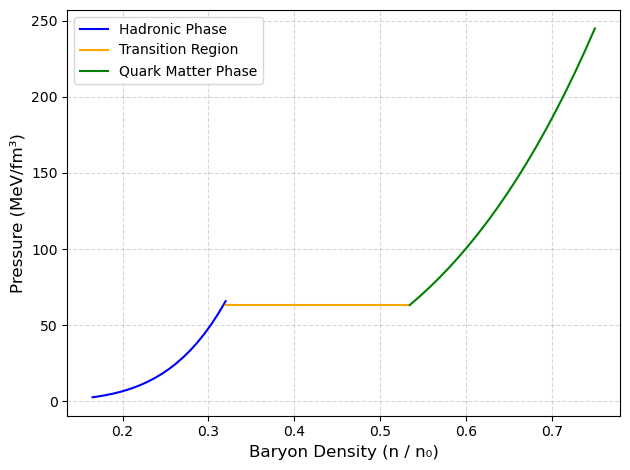

In [10]:
# Plotting each segment
plt.plot(n1_b, P1_b, label='Hadronic Phase', color='blue')
plt.plot(n2_b, P2_b, label='Transition Region', color='orange')
plt.plot(n3_b, P3_b, label='Quark Matter Phase', color='green')

# Axis labels and title
plt.xlabel('Baryon Density (n / n₀)', fontsize=12)
plt.ylabel('Pressure (MeV/fm³)', fontsize=12)
#plt.title('Piecewise Polytropic EoS', fontsize=14)

# Grid, legend, and layout
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

In [12]:
n1_b = np.linspace(n_b[0], n_b[1], 20)
P1_b = P_from_nb(n1_b, K_b[0], Gam_b[0])
mu1_b = mu_from_nb(n1_b, K_b[0], Gam_b[0], m0[0])
e1_b = e_from_n(n1_b, K_b[0], Gam_b[0], m0[0])
cs_1 = cs(mu1_b,K_b[0],Gam_b[0],n_b[0])

n2_b = np.linspace(n_b[1], n_b[2], 20)
P2_b = P_from_nb(n2_b, K_b[1], Gam_b[1])
mu2_b = mu_from_nb(n2_b, K_b[1], Gam_b[1], m0[1])
e2_b = e_from_n(n2_b, K_b[1], Gam_b[1], m0[1])
cs_2 = cs(mu2_b,K_b[1],Gam_b[1],n_b[1])

n3_b = np.linspace(n_b[2], n_b[3], 20)
P3_b = P_from_nb(n3_b, K_b[2], Gam_b[2])
mu3_b = mu_from_nb(n3_b, K_b[2], Gam_b[2], m0[2])
e3_b = e_from_n(n3_b, K_b[2], Gam_b[2], m0[2])
cs_3 = cs(mu3_b,K_b[2],Gam_b[2],n_b[2])

n4_b = np.linspace(n_b[3], n_b[4], 20)
P4_b = P_from_nb(n4_b, K_b[3], Gam_b[3])
mu4_b = mu_from_nb(n4_b, K_b[3], Gam_b[3], m0[3])
e4_b = e_from_n(n4_b, K_b[3], Gam_b[3], m0[3])
cs_4 = cs(mu4_b,K_b[3],Gam_b[3],n_b[3])


P_arr = np.concatenate((P1_b[1:-1], P2_b[1:-1], P3_b[1:-1], P4_b[1:-1]))
e_arr = np.concatenate((e1_b[1:-1], e2_b[1:-1], e3_b[1:-1], e4_b[1:-1]))
n_arr = np.concatenate((n1_b[1:-1], n2_b[1:-1], n3_b[1:-1], n4_b[1:-1]))
mu_arr = np.concatenate((mu1_b[1:-1], mu2_b[1:-1], mu3_b[1:-1], mu4_b[1:-1]))
#cs_arr = np.concatenate((cs_1[1:-1],cs_2[1:-1],cs_3,cs_4))
cs2 = np.gradient(P_arr,e_arr)

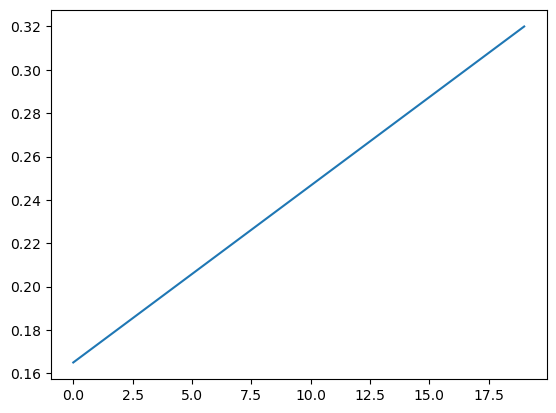

In [13]:
plt.plot(n1_b)

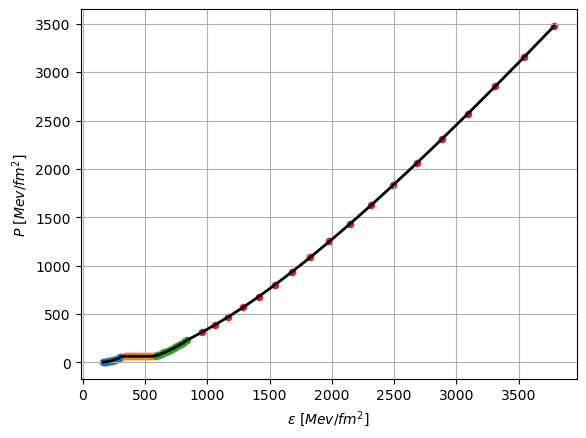

In [14]:
plt.scatter(e1_b[1:-1], P1_b[1:-1],s=20);
plt.scatter(e2_b[1:-1], P2_b[1:-1],s=20);
plt.scatter(e3_b[1:-1], P3_b[1:-1],s=20);
plt.scatter(e4_b[1:-1], P4_b[1:-1],s=20);

plt.plot(e_arr, P_arr, linewidth = 2, color = "black");
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

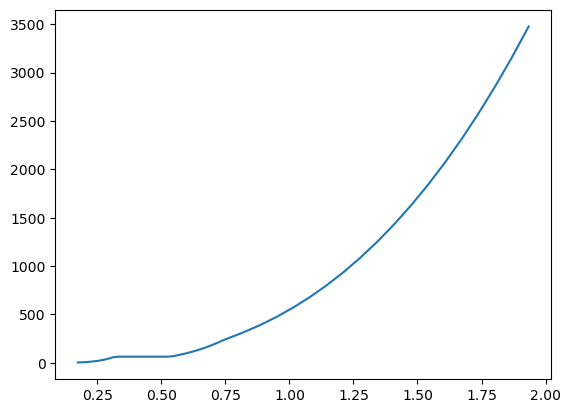

In [15]:
plt.plot(n_arr,P_arr)

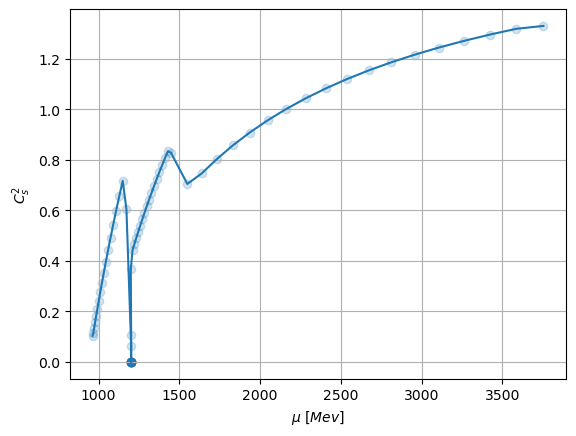

In [16]:
plt.scatter(mu_arr,cs2,alpha=0.2);
plt.plot(mu_arr,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev]$")
plt.ylabel(r"$C_s^2$")
plt.show();

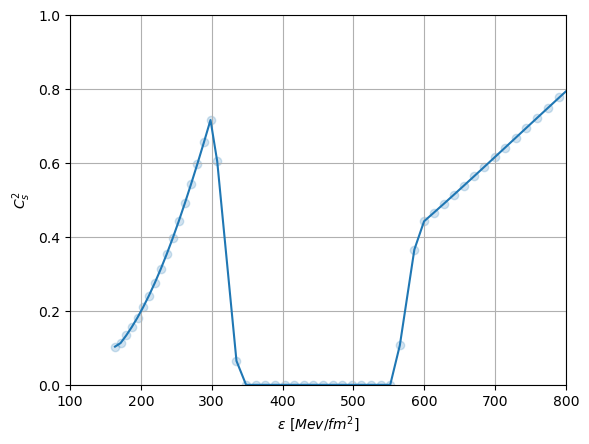

In [17]:
plt.scatter(e_arr,cs2,alpha=0.2);
plt.plot(e_arr,cs2)
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.xlim(100,800)
plt.ylim(0, 1)
plt.show();

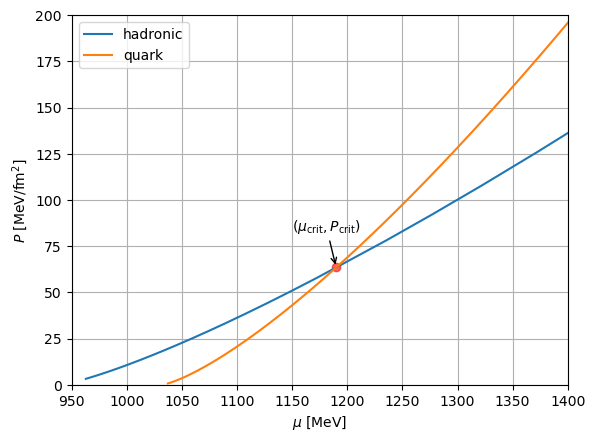

In [20]:
n_arr1 = np.concatenate((n1_b[1:-1], n2_b[1:-1], n3_b[1:-1]))

mu1_b = mu_from_nb(n_arr, K_b[0], Gam_b[0], m0[0])
mu3_b = mu_from_nb(n_arr1, K_b[2], Gam_b[2], m0[2])
mu4_b = mu_from_nb(n4_b[1:-1], K_b[3], Gam_b[3], m0[3])
mu_quark = np.concatenate((mu3_b,mu4_b))

P_1_all = P_from_nb(n_arr, K_b[0], Gam_b[0])
P_3_all = P_from_nb(n_arr, K_b[2], Gam_b[2])

plt.plot(mu1_b, P_1_all, label="hadronic")
plt.plot(mu_quark, P_3_all, label="quark")

plt.xlabel(r"$\mu \ [\mathrm{MeV}]$")
plt.ylabel(r"$P \ [\mathrm{MeV/fm^2}]$")
plt.legend()
plt.scatter(x_intersect, y_intersect, color="red", alpha=0.6, label=r"$(\mu_{\mathrm{crit}}, P_{\mathrm{crit}})$")

# Annotate the critical point
plt.annotate(r"$(\mu_{\mathrm{crit}}, P_{\mathrm{crit}})$", 
             xy=(x_intersect, y_intersect), 
             xytext=(x_intersect - 40, y_intersect + 20),
             arrowprops=dict(arrowstyle='->', color='black'),
             fontsize=10)

plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.grid()
plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


The index is : 417 the mu value is:  1189.8348348348347


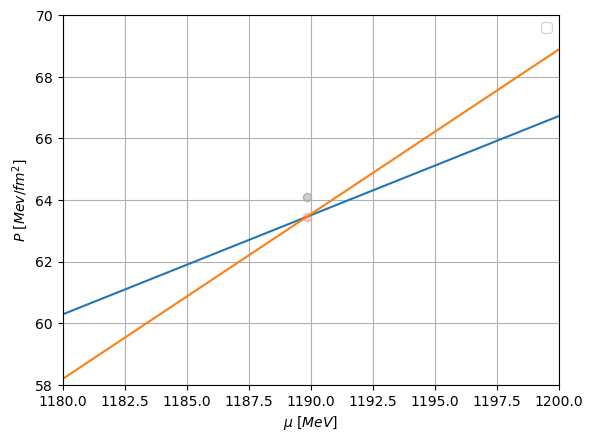

1189.8348348348347 63.452713316194014
Critical Chemical Potential is, mu_c: 1189.8348348348347


In [19]:
x1 = np.array(mu1_b)
y1 = np.array(P_1_all)

x2 = np.array(mu_quark)
y2 = np.array(P_3_all)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1050, 1385, 1000)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)


y_diff = np.abs(P_h_int_func(mu_new) - P_q_int_func(mu_new))
print("The index is :",np.argmin(y_diff), "the mu value is: ", mu_new[np.argmin(y_diff)])
x_intersect = mu_new[np.argmin(y_diff)]
y_intersect = P_h_int_func(x_intersect)
#%%
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([58,70])
plt.xlim([1180,1200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()
plt.show()
print(x_intersect, y_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)

The index is: 624 the mu value is: 1189.859906604403
Critical Chemical Potential is, mu_c: 1189.859906604403


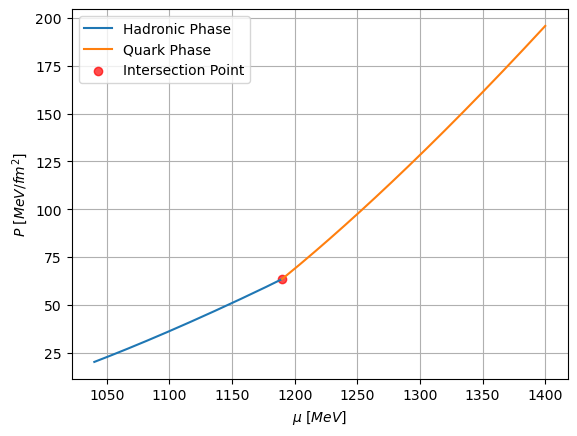

In [78]:
# Assuming mu1_b, P_1_all, mu_quark, and P_3_all are already defined
x1 = np.array(mu1_b)
y1 = np.array(P_1_all)

x2 = np.array(mu_quark)
y2 = np.array(P_3_all)

P_h_int_func = interpolate.interp1d(x1, y1)
P_q_int_func = interpolate.interp1d(x2, y2)

mu_new = np.linspace(1040, 1400, 1500)
P_had_array = P_h_int_func(mu_new)
P_quark_array = P_q_int_func(mu_new)

# Calculate the difference and find the intersection
y_diff = np.abs(P_had_array - P_quark_array)
index_intersect = np.argmin(y_diff)
x_intersect = mu_new[index_intersect]
y_intersect = P_had_array[index_intersect]

print("The index is:", index_intersect, "the mu value is:", x_intersect)
print("Critical Chemical Potential is, mu_c:", x_intersect)

# Split the arrays at the intersection point
mu_had = mu_new[:index_intersect + 1]
P_had = P_had_array[:index_intersect + 1]
mu_quark_2 = mu_new[index_intersect:]
P_quark_2 = P_quark_array[index_intersect:]

# Plotting the updated arrays
plt.plot(mu_had, P_had, label='Hadronic Phase')
plt.plot(mu_quark_2, P_quark_2, label='Quark Phase')
plt.scatter(x_intersect, y_intersect, color="red", alpha=0.7, label='Intersection Point')
plt.ylim()
plt.xlim()
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
plt.legend()
plt.grid()
plt.show()

In [79]:
@jit(nopython=True)
def quad_P(mu_c, mu, alpha, beta, delP, P_c):
    t1 = alpha*(mu - mu_c)**2
    t2 = beta*(mu - mu_c)
    t3 = (1+delP)*P_c
    re = t1 + t2 + t3
    return re

@jit(nopython=True)
def alpha(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        re = (t1 - t2)/(mu_c_q - mu_c_h)
    return re

@jit(nopython=True)
def beta(delP, P_q, P_h, P_c, mu_c, mu_c_h, mu_c_q):
    if (mu_c_q - mu_c_h) == 0 or (mu_c_h - mu_c) == 0 or (mu_c_q - mu_c) == 0:
        re = -1
    else:
        t1 = (P_q - (1+delP)*P_c)/(mu_c_q - mu_c)
        t2 = (P_h - (1+delP)*P_c)/(mu_c_h - mu_c)
        t3 = (P_q - P_h)/(mu_c_q - mu_c_h)
        re = t1 + t2 - t3
    return re

1187.4583055370247 1192.2615076717811


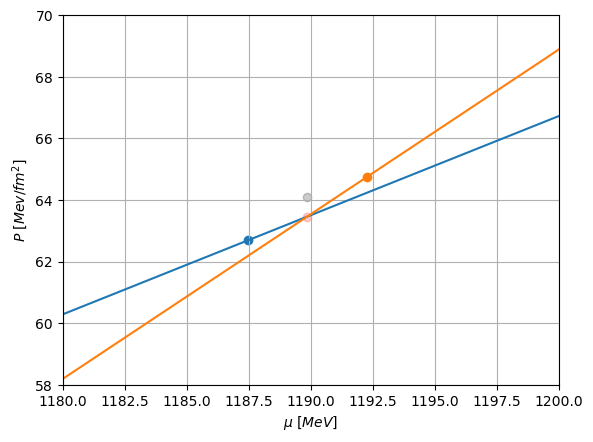

In [80]:
mu_c_h = mu_new[np.argmin(y_diff) - 10]
mu_c_q = mu_new[np.argmin(y_diff) + 10]
P_h = P_h_int_func(mu_c_h)
P_q = P_q_int_func(mu_c_q)

print(mu_c_h, mu_c_q)
plt.scatter(mu_c_h, P_h)
plt.scatter(mu_c_q, P_q)
plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)
plt.scatter(x_intersect, y_intersect*(1 + 0.01), color = "black", alpha = 0.2)
plt.ylim([58,70])
plt.xlim([1180,1200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.grid()
plt.show()

In [81]:
y_intersect

63.460782642527796

In [28]:
delta_P_arr = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10]
A = []
B = []
mu_c_h_arr  = []
mu_c_q_arr = []
P_c_h_arr = []
P_c_q_arr = []


for z in range(len(delta_P_arr)):
    delta_P = delta_P_arr[z]
    found = False
    for i in range(len(mu_new)):
        if found:
            break
        mu_c_h = mu_new[i]
        for j in range(len(mu_new)):
            mu_c_q = mu_new[j]
            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            if alp > 0:
                P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)
                m_h_P_diff = [x - y for x, y in zip(P_m[:np.argmin(y_diff)], P_had_array[:np.argmin(y_diff)])]
                m_q_P_diff = [x - y for x, y in zip(P_m[np.argmin(y_diff):], P_quark_array[np.argmin(y_diff):])]

                if min(m_h_P_diff) >= 0 and min(m_q_P_diff) >= 0:
                    print(min(m_h_P_diff), min(m_q_P_diff))
                    A.append(alp)
                    B.append(bet)
                    mu_c_h_arr.append(mu_c_h)
                    mu_c_q_arr.append(mu_c_q)
                    P_c_h_arr.append(P_h)
                    P_c_q_arr.append(P_q)
                    found = True
                    break

    if found:
        continue


print(len(A), A, B)

0.0 0.0
0.0 0.0
0.0 0.0
0.0 0.0
0.0 0.0
0.0 0.0
7.105427357601002e-15 0.0
7.105427357601002e-15 0.0
8 [0.004892100657942246, 0.0026573985961465926, 0.0018966231619799484, 0.001513070067364713, 0.0011256158392305181, 0.0010138002340616037, 0.000929466599657586, 0.0008103438178658626] [0.4268014654482355, 0.4296551033528423, 0.4319394644011815, 0.4339754369885776, 0.43759094539582316, 0.4392130363820171, 0.4407233165127479, 0.44344310773291024]


In [48]:
0.13*P1_b[-1]

8.546721019136129

In [82]:
delta_P_arr = [0.02, 0.05, 0.08, 0.10, 0.12]

In [83]:
from itertools import product
import numpy as np

def find_valid_parameters(delta_P_arr, mu_new, P_h_int_func, P_q_int_func, alpha, beta, quad_P, y_intersect, x_intersect, y_diff, P_had_array, P_quark_array):
    A, B = [], []
    mu_c_h_arr, mu_c_q_arr = [], []
    P_c_h_arr, P_c_q_arr = [], []
    delta_P_found = []

    for delta_P in delta_P_arr:
        found = False

        # Iterate through all combinations of mu_c_h and mu_c_q
        for mu_c_h, mu_c_q in product(mu_new, repeat=2):
            if found:
                break

            P_h = P_h_int_func(mu_c_h)
            P_q = P_q_int_func(mu_c_q)

            alp = alpha(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)
            bet = beta(delta_P, P_q, P_h, y_intersect, x_intersect, mu_c_h, mu_c_q)

            # Check if alpha is positive
            if alp <= 0:
                continue

            # Calculate the mixed phase pressure
            P_m = quad_P(x_intersect, mu_new, alp, bet, delta_P, y_intersect)

            # Split the pressure difference calculation
            min_idx = np.argmin(y_diff)
            m_h_P_diff = P_m[:min_idx] - P_had_array[:min_idx]
            m_q_P_diff = P_m[min_idx:] - P_quark_array[min_idx:]

            # Validate the pressure conditions
            if np.all(m_h_P_diff >= 0) and np.all(m_q_P_diff >= 0):
                print(np.min(m_h_P_diff), np.min(m_q_P_diff))

                A.append(alp)
                B.append(bet)
                mu_c_h_arr.append(mu_c_h)
                mu_c_q_arr.append(mu_c_q)
                P_c_h_arr.append(P_h)
                P_c_q_arr.append(P_q)
                delta_P_found.append(delta_P)
                found = True

    print(f"Found {len(A)} valid sets of parameters.")
    return A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found

In [84]:
A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, delta_P_found = find_valid_parameters(delta_P_arr, mu_new, P_h_int_func, P_q_int_func, alpha, beta, quad_P, y_intersect, x_intersect, y_diff, P_had_array, P_quark_array)

0.0 0.0
0.0 0.0
3.552713678800501e-15 0.0
3.552713678800501e-15 0.0
Found 4 valid sets of parameters.


In [85]:
delta_P_found

[0.02, 0.05, 0.1, 0.12]

In [153]:
A.insert(4, (A[3] + A[4]) / 2)
B.insert(4, (B[3] + B[4]) / 2)
mu_c_h_arr.insert(4, (mu_c_h_arr[3] + mu_c_h_arr[4]) / 2)
mu_c_q_arr.insert(4, (mu_c_q_arr[3] + mu_c_q_arr[4]) / 2)
P_c_h_arr.insert(4, (P_c_h_arr[3] + P_c_h_arr[4]) / 2)
P_c_q_arr.insert(4, (P_c_q_arr[3] + P_c_q_arr[4]) / 2)
delta_P_found.insert(4, (delta_P_found[3] + delta_P_found[4]) / 2)

In [86]:
def find_first_larger_index(lst, value):
    return next((i for i, x in enumerate(lst) if x > value), None)

def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients
from TOV_Solver import generate_mr_curve

In [87]:
def mixed_phase(mu_total, p_total,n_total, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, mu_crit, P_crit):
    P_arr_dp = []
    E_arr_dp = []
    number_density_dp = []
    mu_arr_dp = []

    for i in range(len(A)):
        index_1 = find_first_larger_index(mu_total, mu_c_h_arr[i])
        index_2 = find_first_larger_index(mu_total, mu_c_q_arr[i])

        mu_mixed = np.linspace(mu_total[index_1], mu_total[index_2], len(mu_total[index_1:index_2]))

        P_m = quad_P(mu_crit, mu_mixed, A[i], B[i], delta_P_arr[i], P_crit)
        P_had_half = p_total[:index_1]
        P_quark_half = p_total[index_2:]

        grad_had = n_total[:index_1]
        grad_m = gradient(P_m,mu_mixed)
        grad_quark = n_total[index_2:]

        mu_arr = np.concatenate((mu_total[:index_1], mu_mixed[:-1], mu_total[index_2:]))

        grad_dummy = np.concatenate((grad_had,grad_m,grad_quark))
        P_arr_dummy = np.concatenate((P_had_half,P_m[:-1],P_quark_half))

        e_dummy = (grad_dummy*mu_arr)-P_arr_dummy

        P_arr_dp.append(P_arr_dummy)
        E_arr_dp.append(e_dummy)
        number_density_dp.append(grad_dummy)
        mu_arr_dp.append(mu_arr)

    return P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp

In [88]:
P_arr_dp, E_arr_dp, number_density_dp, mu_arr_dp = mixed_phase(mu_arr, P_arr, n_arr, A, B, mu_c_h_arr, mu_c_q_arr, P_c_h_arr, P_c_q_arr, x_intersect, y_intersect)

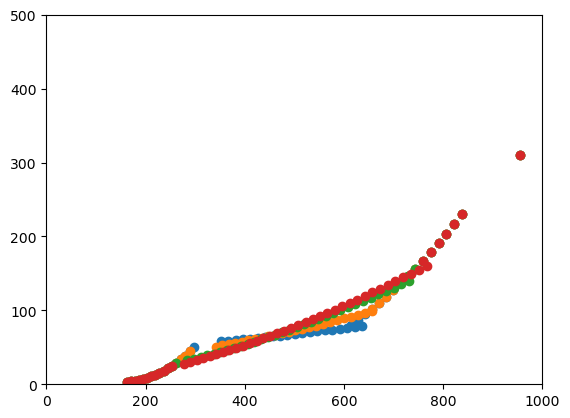

In [90]:
for i in range(4):
    plt.scatter(E_arr_dp[i],P_arr_dp[i])
plt.xlim(0,1000)
plt.ylim(0,500)
plt.show()

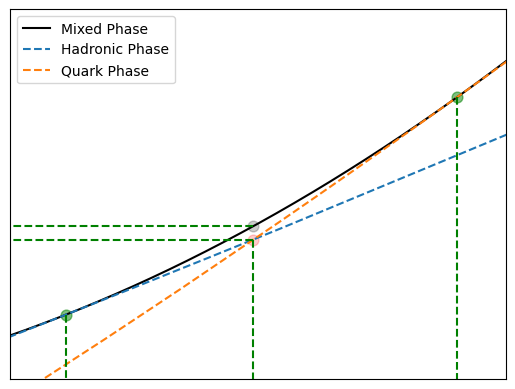

In [158]:
P_m2 = quad_P(x_intersect, mu_new, A[1], B[1], delta_P_arr[1], y_intersect)


plt.plot(mu_new, P_m2,label = "Mixed Phase",color = "black")
plt.plot(mu_new, P_had_array,linestyle="--",label = "Hadronic Phase")
plt.plot(mu_new, P_quark_array,linestyle="--",label = "Quark Phase")


plt.scatter(mu_c_h_arr[1], P_c_h_arr[1], color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr[1], P_c_q_arr[1], color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

x=[mu_c_h_arr[1],mu_c_h_arr[1]]
y=[P_c_h_arr[1],0]

x1 = [mu_c_q_arr[1],mu_c_q_arr[1]]
y1 = [P_c_q_arr[1],0]

plt.plot(x1,y1,color='green',linestyle="--")

plt.plot(x,y,color='green',linestyle="--")

x3 = [x_intersect,0]
y3 = [y_intersect,y_intersect]
y4 = [y_intersect*(1 + delta_P_arr[1]),y_intersect*(1 + delta_P_arr[1])]

x5 = [x_intersect,x_intersect]
y5 = [y_intersect,0]
plt.plot(x5,y5,color='green',linestyle="--")
plt.plot(x3,y3,color='green',linestyle="--")
plt.plot(x3,y4,color='green',linestyle="--")

plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[1]), color = "black", alpha = 0.2, s = 60)

plt.xlabel(r"Chemical Potential")
plt.ylabel(r"Pressure")
# Remove x and y labels
plt.xlabel('')  # Set x-axis label to empty
plt.ylabel('')

# Alternatively, hide the ticks completely if desired
plt.xticks([])  # Remove x-axis ticks
plt.yticks([]) 
plt.xlim([1160,1220])
plt.ylim([50,85])
plt.legend()


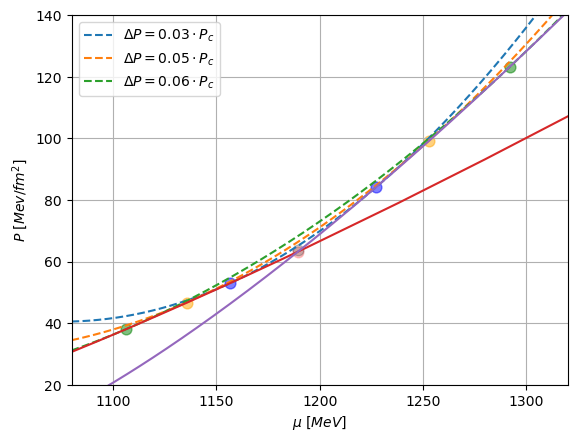

In [159]:
P_m3 = quad_P(x_intersect, mu_new, A[2], B[2], delta_P_arr[2], y_intersect)
P_m5 = quad_P(x_intersect, mu_new, A[4], B[4], delta_P_arr[4], y_intersect)
P_m6 = quad_P(x_intersect, mu_new, A[7], B[7], delta_P_arr[7], y_intersect)



plt.plot(mu_new, P_m3, linestyle="--", label=fr"$\Delta P = 0.03 \cdot P_c$")
plt.plot(mu_new, P_m5, linestyle="--", label=fr"$\Delta P = 0.05 \cdot P_c$")
plt.plot(mu_new, P_m6, linestyle="--", label=fr"$\Delta P = 0.06 \cdot P_c$")


plt.scatter(mu_c_h_arr[2], P_c_h_arr[2], color = "blue", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr[2], P_c_q_arr[2], color = "blue", alpha = 0.5, s = 60)

plt.scatter(mu_c_h_arr[4], P_c_h_arr[4], color = "orange", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr[4], P_c_q_arr[4], color = "orange", alpha = 0.5, s = 60)

plt.scatter(mu_c_h_arr[7], P_c_h_arr[7], color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr[7], P_c_q_arr[7], color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[0]), color = "black", alpha = 0.2, s = 60)

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.xlim([1080,1320])
plt.ylim([20,140])
plt.legend()
plt.grid()

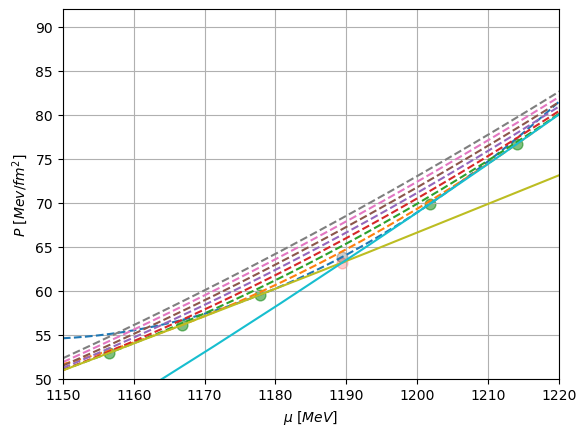

In [160]:
P_m1 = quad_P(x_intersect, mu_new, A[0], B[0], delta_P_arr[0], y_intersect)
P_m2 = quad_P(x_intersect, mu_new, A[1], B[1], delta_P_arr[1], y_intersect)
P_m3 = quad_P(x_intersect, mu_new, A[2], B[2], delta_P_arr[2], y_intersect)
P_m4 = quad_P(x_intersect, mu_new, A[3], B[3], delta_P_arr[3], y_intersect)
P_m5 = quad_P(x_intersect, mu_new, A[4], B[4], delta_P_arr[4], y_intersect)
P_m6 = quad_P(x_intersect, mu_new, A[5], B[5], delta_P_arr[5], y_intersect)
P_m7 = quad_P(x_intersect, mu_new, A[6], B[6], delta_P_arr[6], y_intersect)
P_m8 = quad_P(x_intersect, mu_new, A[7], B[7], delta_P_arr[7], y_intersect)


plt.plot(mu_new, P_m1, linestyle="--")
plt.plot(mu_new, P_m2, linestyle="--")
plt.plot(mu_new, P_m3, linestyle="--")
plt.plot(mu_new, P_m4, linestyle="--")
plt.plot(mu_new, P_m5, linestyle="--")
plt.plot(mu_new, P_m6, linestyle="--")
plt.plot(mu_new, P_m7, linestyle="--")
plt.plot(mu_new, P_m8, linestyle="--")


plt.scatter(mu_c_h_arr, P_c_h_arr, color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr, P_c_q_arr, color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[0]), color = "black", alpha = 0.2, s = 60)

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.xlim([1150,1220])
plt.ylim([50,92])
plt.grid()

In [161]:
P_m7 = quad_P(x_intersect, mu_new, A[6], B[6], delta_P_arr[6], y_intersect, label = f"$\Delta P = 0.0{1}*P_c$")
P_m3 = quad_P(x_intersect, mu_new, A[2], B[2], delta_P_arr[2], y_intersect, label = f"$\Delta P = 0.0{1}*P_c$")
P_m5 = quad_P(x_intersect, mu_new, A[4], B[4], delta_P_arr[4], y_intersect, label = f"$\Delta P = 0.0{1}*P_c$")

plt.plot(mu_new, P_m7, linestyle="--", label = f"$\Delta P = 0.0{7}*P_c$")
plt.plot(mu_new, P_m5, linestyle="--",label = f"$\Delta P = 0.0{5}*P_c$")
plt.plot(mu_new, P_m3, linestyle="--",label = f"$\Delta P = 0.0{3}*P_c$")

plt.scatter(mu_c_h_arr[:3], P_c_h_arr[:3], color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr[:3], P_c_q_arr[:3], color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
#plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[0]), color = "black", alpha = 0.2, s = 60)

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([1000,1130])
plt.ylim([50,85])
plt.grid()

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:5: SyntaxWarning: invalid escape sequence '\D'
<>:6: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:2: SyntaxWarning: invalid escape sequence '\D'
<>:3: SyntaxWarning: invalid escape sequence '\D'
<>:5: SyntaxWarning: invalid escape sequence '\D'
<>:6: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13126/13782458.py:1: SyntaxWarning: invalid escape sequence '\D'
  P_m7 = quad_P(x_intersect, mu_new, A[6], B[6], delta_P_arr[6], y_intersect, label = f"$\Delta P = 0.0{1}*P_c$")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13126/13782458.py:2: SyntaxWarning: invalid escape sequence '\D'
  P_m3 = quad_P(x_intersect, mu_new, A

TypeError: too many arguments: expected 6, got 7

<>:6: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:8: SyntaxWarning: invalid escape sequence '\D'
<>:6: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:8: SyntaxWarning: invalid escape sequence '\D'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13126/3180725887.py:6: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(mu_new, P_m1, linestyle="--", label = f"$\Delta P = 0.0{1}*P_c$")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13126/3180725887.py:7: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(mu_new, P_m2, linestyle="--",label = f"$\Delta P = 0.0{2}*P_c$")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13126/3180725887.py:8: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(mu_new, P_m3, linestyle="--",label = f"$\Delta P = 0.0{3}*P_c$")


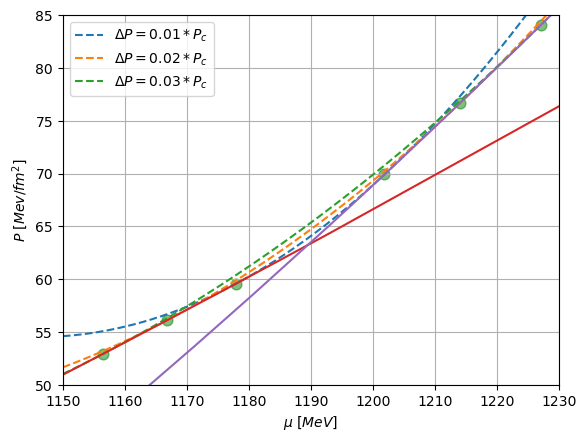

In [162]:
P_m1 = quad_P(x_intersect, mu_new, A[0], B[0], delta_P_arr[0], y_intersect)
P_m2 = quad_P(x_intersect, mu_new, A[1], B[1], delta_P_arr[1], y_intersect)
P_m3 = quad_P(x_intersect, mu_new, A[2], B[2], delta_P_arr[2], y_intersect)


plt.plot(mu_new, P_m1, linestyle="--", label = f"$\Delta P = 0.0{1}*P_c$")
plt.plot(mu_new, P_m2, linestyle="--",label = f"$\Delta P = 0.0{2}*P_c$")
plt.plot(mu_new, P_m3, linestyle="--",label = f"$\Delta P = 0.0{3}*P_c$")


plt.scatter(mu_c_h_arr[:3], P_c_h_arr[:3], color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr[:3], P_c_q_arr[:3], color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
#plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[0]), color = "black", alpha = 0.2, s = 60)

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([1150,1230])
plt.ylim([50,85])
plt.grid()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


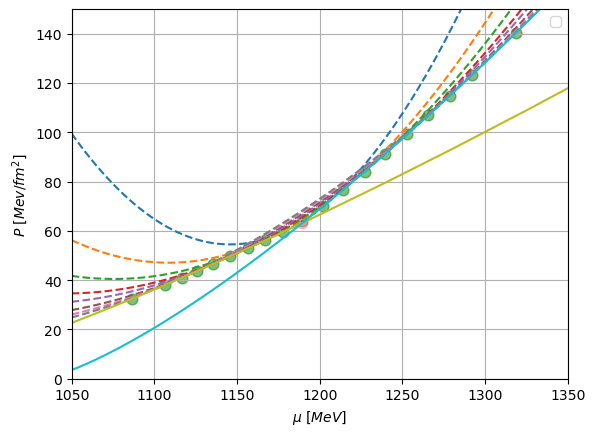

In [163]:
P_m1 = quad_P(x_intersect, mu_new, A[0], B[0], delta_P_arr[0], y_intersect)
P_m2 = quad_P(x_intersect, mu_new, A[1], B[1], delta_P_arr[1], y_intersect)
P_m3 = quad_P(x_intersect, mu_new, A[2], B[2], delta_P_arr[2], y_intersect)
P_m4 = quad_P(x_intersect, mu_new, A[3], B[3], delta_P_arr[3], y_intersect)
P_m5 = quad_P(x_intersect, mu_new, A[4], B[4], delta_P_arr[4], y_intersect)
P_m6 = quad_P(x_intersect, mu_new, A[5], B[5], delta_P_arr[5], y_intersect)
P_m7 = quad_P(x_intersect, mu_new, A[6], B[6], delta_P_arr[6], y_intersect)
P_m8 = quad_P(x_intersect, mu_new, A[7], B[7], delta_P_arr[7], y_intersect)


plt.plot(mu_new, P_m1, linestyle="--")
plt.plot(mu_new, P_m2, linestyle="--")
plt.plot(mu_new, P_m3, linestyle="--")
plt.plot(mu_new, P_m4, linestyle="--")
plt.plot(mu_new, P_m5, linestyle="--")
plt.plot(mu_new, P_m6, linestyle="--")
plt.plot(mu_new, P_m7, linestyle="--")
plt.plot(mu_new, P_m8, linestyle="--")


plt.scatter(mu_c_h_arr, P_c_h_arr, color = "green", alpha = 0.5, s = 60)
plt.scatter(mu_c_q_arr, P_c_q_arr, color = "green", alpha = 0.5, s = 60)
#plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2)

plt.plot(mu_new, P_had_array)
plt.plot(mu_new, P_quark_array)
plt.scatter(x_intersect, y_intersect, color = "red", alpha = 0.2, s = 60)
plt.scatter(x_intersect, y_intersect*(1 + delta_P_arr[0]), color = "black", alpha = 0.2, s = 60)

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([1050,1350])
plt.ylim([0,150])
plt.grid()

In [165]:
mu_new

array([1040.        , 1040.24016011, 1040.48032021, ..., 1399.51967979,
       1399.75983989, 1400.        ])

In [166]:
mu_c_h_arr

[1177.8519012675117,
 1166.8045363575718,
 1156.4776517678451,
 1145.6704469646431,
 1135.7038025350234,
 1125.7371581054035,
 1116.3709139426285,
 1106.2841894596397,
 1086.591060707138]

<>:19: SyntaxWarning: invalid escape sequence '\D'
<>:19: SyntaxWarning: invalid escape sequence '\D'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13547/1184274798.py:19: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(e_10_req, P_10_reqd, linestyle="--", label=f"$\Delta_P = 0.0{1 + i}$")


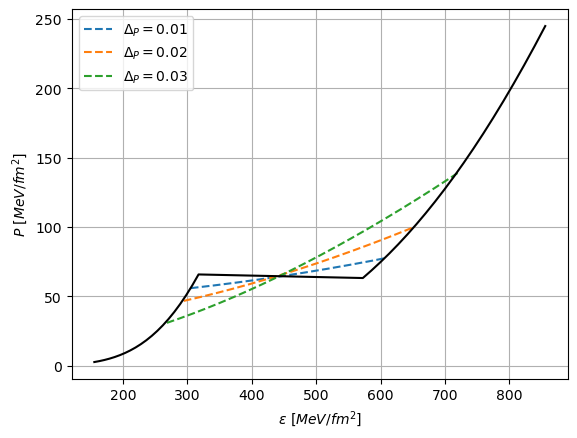

In [91]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)

# Define the indices you want to plot for
indices_to_plot = [0, 1, 2]

for i in indices_to_plot:
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = find_first_larger_index(mu_new_arr, mu_c_h_arr[i])
    ind_q0 = find_first_larger_index(mu_new_arr, mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1 * mu_10_req) - P_10_reqd

    plt.plot(e_10_req, P_10_reqd, linestyle="--", label=f"$\Delta_P = 0.0{1 + i}$")

# Plot additional curves
plt.plot(np.concatenate((e1_b,e3_b)), np.concatenate((P1_b, P3_b)), color = 'black')
#plt.plot(e1_b, P1_b)
#plt.plot(e2_b, P2_b)
#plt.plot(e3_b, P3_b)
plt.grid()

plt.xlabel(r"$\epsilon \ [MeV/fm^2]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
plt.legend(loc="upper left")


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


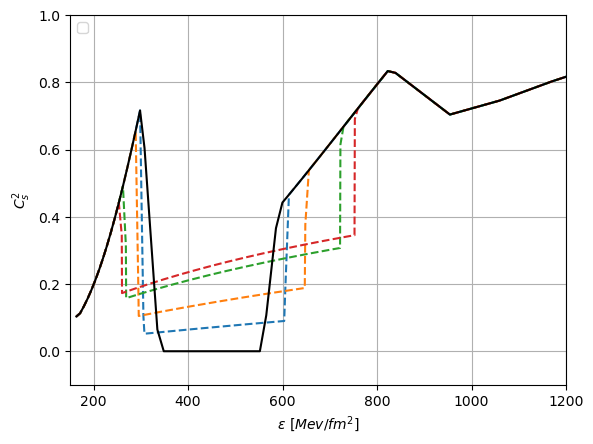

In [97]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(np.concatenate((P3_b, P4_b)))

# Define the indices you want to plot for
indices_to_plot = [0, 1, 2, 3]

#m,r =[], []
plt.figure()
for i in indices_to_plot:
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = find_first_larger_index(mu_new_arr, mu_c_h_arr[i])
    ind_q0 = find_first_larger_index(mu_new_arr, mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]

    ind_h0h = find_first_larger_index(P_arr, P_10_reqd[0])
    ind_q0q = find_first_larger_index(P_arr,P_10_reqd[-1])

    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1 * mu_10_req) - P_10_reqd
    cs_10_req = np.gradient(P_10_reqd, e_10_req)

    P_whole = np.concatenate((P_arr[:ind_h0h], P_10_reqd, P_arr[ind_q0q:]))
    e_whole = np.concatenate((e_arr[:ind_h0h], e_10_req, e_arr[ind_q0q:]))
    cs_whole = np.concatenate((cs2[:ind_h0h], cs_10_req, cs2[ind_q0q:]))

    #m_whole, r_whole, l, c = generate_mr_curve(e_whole, P_whole)
    #m.append(m_whole)
    #r.append(r_whole)
    #plt.plot(e_whole, P_whole)
    plt.plot(e_whole, cs_whole, linestyle="--")
plt.plot(e_arr, cs2,  color = "black")
plt.xlim(150,1200)
plt.ylim(-0.1,1)
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [93]:
len(m)

4

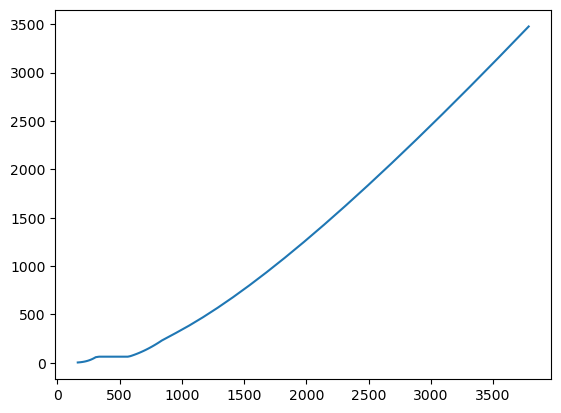

In [94]:
plt.plot(e_arr, P_arr)

In [ ]:
m1,r1, l1,c1 = generate_mr_curve(e_arr, P_arr)

In [59]:
for i in range(len(cs2)):
    if cs2[i]<0:
        cs2[i] = 0

In [60]:
m_hehe, r_hehe = m[4], r[4]

IndexError: list index out of range

In [61]:
k = [2]*len(m[3])

IndexError: list index out of range

In [62]:
len(m)

3

In [40]:
m[4] = ((np.array(m[3]) + np.array(m[5])) / 2).tolist()
r[4] = ((np.array(r[3]) + np.array(r[5])) / 2).tolist()

NameError: name 'm' is not defined

In [63]:
m12, r12, l12,c12 = generate_mr_curve(e_arr, P_arr)

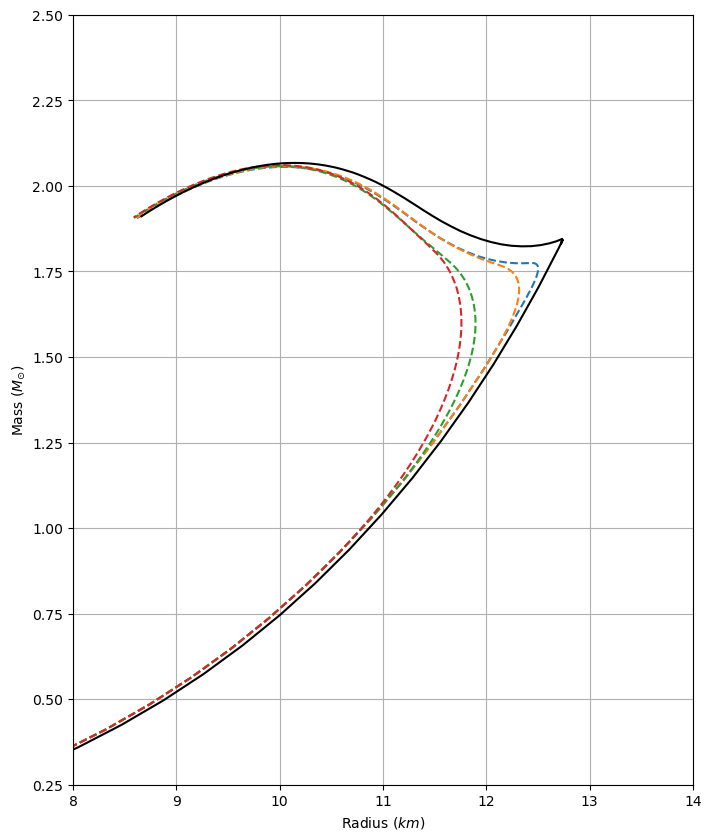

In [95]:
plt.figure(figsize=(8, 10))
for i in range(len(m)):
    plt.plot(m[i], r[i], linestyle="--")
    plt.xlim(8,14)
    plt.ylim(0.25,2.5)
plt.plot(m12, r12, color = 'black')
plt.xlabel(r"Radius $(km)$")  
plt.ylabel(r"Mass $(M_{\odot})$")  
plt.grid()

<>:34: SyntaxWarning: invalid escape sequence '\D'
<>:34: SyntaxWarning: invalid escape sequence '\D'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13547/1592838698.py:34: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(e_10_req, cs2_10_req, linestyle="--", label=f"$\Delta P = 0.0{1 + i}$")
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_13547/1592838698.py:34: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(e_10_req, cs2_10_req, linestyle="--", label=f"$\Delta P = 0.0{1 + i}$")


IndexError: list index out of range

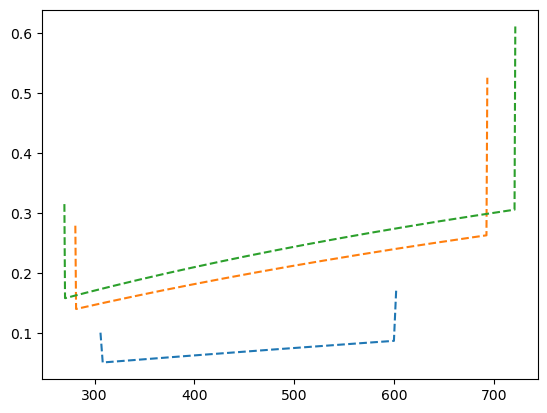

In [65]:
import numpy as np
import matplotlib.pyplot as plt

mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)

# Define the indices you want to plot for
indices_to_plot = [0, 1, 2, 3, 4, 5, 6, 7]

e_all = []
P_all = []
cs2_all = []

for i in indices_to_plot:
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1 * mu_10_req) - P_10_reqd  # Energy density

    # Compute speed of sound squared C_s^2 = dP/dε
    cs2_10_req = np.gradient(P_10_reqd, e_10_req)

    # Store values for merging
    e_all.append(e_10_req)
    P_all.append(P_10_reqd)
    cs2_all.append(cs2_10_req)

    plt.plot(e_10_req, cs2_10_req, linestyle="--", label=f"$\Delta P = 0.0{1 + i}$")

# Find closest reference indices for transition
ind_h_ref = np.argmin(np.abs(e1_b - min(e_all[0])))  # Closest to start of mixed phase
ind_q_ref = np.argmin(np.abs(e3_b - max(e_all[-1])))  # Closest to end of mixed phase

# Ensure correct slicing
e_had_ref = e1_b[:ind_h_ref]  # Hadronic before transition
P_had_ref = P1_b[:ind_h_ref]

e_quark_ref = e3_b[ind_q_ref:]  # Quark after transition
P_quark_ref = P3_b[ind_q_ref:]

# Concatenating everything
e_combined = np.concatenate((e_had_ref, *e_all, e_quark_ref))
P_combined = np.concatenate((P_had_ref, *P_all, P_quark_ref))

# Debugging: Check array sizes
print("e_combined length:", len(e_combined))
print("P_combined length:", len(P_combined))

# Compute cs2 for the combined curve
cs2_combined = np.gradient(P_combined, e_combined)

# Plot the reference curve with mixed-phase corrections
plt.plot(e_combined, cs2_combined, color='black', label="Reference (with mixed phase)")

plt.grid()
plt.xlabel(r"$\epsilon \ [MeV/fm^3]$")
plt.ylabel(r"$C_s^2$")
plt.legend(loc="upper left")
plt.show()

<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
/var/folders/x2/9k_mqtsx70ngx3zxlc8lbmh00000gn/T/ipykernel_5390/4282611949.py:15: SyntaxWarning: invalid escape sequence '\D'
  plt.plot(e_10_req, P_10_reqd, linestyle = "--", label = f"$\Delta P = 0.0{1+i}*P_c$")


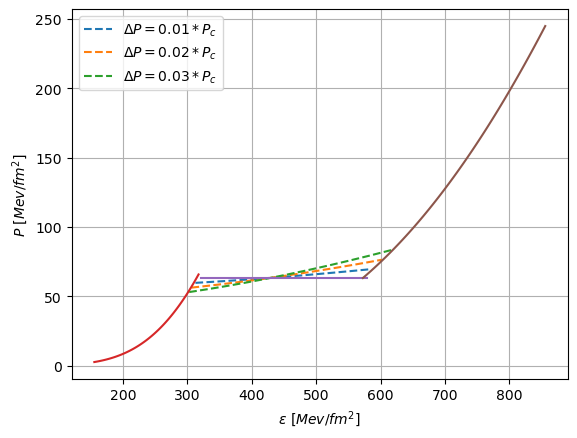

In [23]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)
for i in range(len(mu_c_h_arr[:3])):
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1*mu_10_req)-P_10_reqd

    plt.plot(e_10_req, P_10_reqd, linestyle = "--", label = f"$\Delta P = 0.0{1+i}*P_c$")

plt.plot(e1_b, P1_b)
plt.plot(e2_b, P2_b)
plt.plot(e3_b, P3_b)
plt.grid()
#plt.plot(e4_b, P4_b)
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")

plt.legend(loc="upper left")

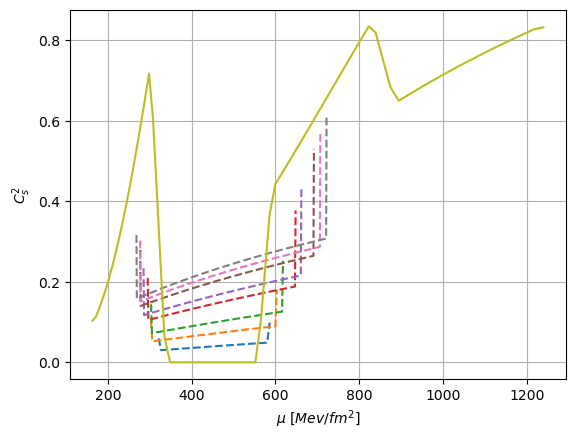

In [39]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)
for i in range(len(mu_c_h_arr)):
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1*mu_10_req)-P_10_reqd
    cs2_10_req = np.gradient(P_10_reqd,e_10_req)

    plt.plot(e_10_req, cs2_10_req, linestyle = "--", label = f"0.0{i}Pc")


#plt.scatter(mu_arr,cs2,alpha=0.2);
plt.plot(e_arr,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.show();

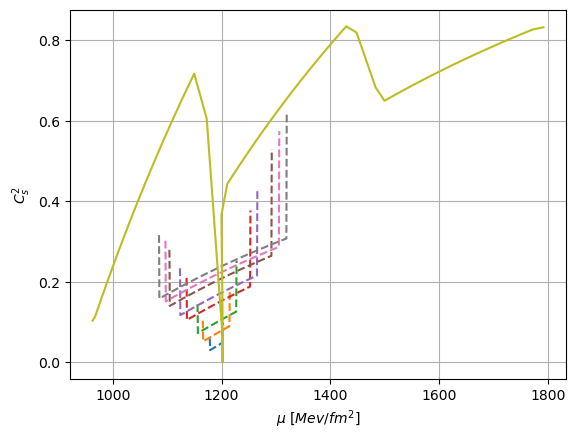

In [40]:
mu_new_arr = list(mu_new)
P_had_array_arr = list(P_had_array)
P_quark_array_arr = list(P_quark_array)
for i in range(len(mu_c_h_arr)):
    P_m1 = quad_P(x_intersect, mu_new, A[i], B[i], delta_P_arr[i], y_intersect)

    ind_h0 = mu_new_arr.index(mu_c_h_arr[i])
    ind_q0 = mu_new_arr.index(mu_c_q_arr[i])

    P_10_reqd = P_m1[ind_h0:ind_q0]
    mu_10_req = mu_new[ind_h0:ind_q0]
    n_10_re1 = np.gradient(P_10_reqd, mu_10_req)
    e_10_req = (n_10_re1*mu_10_req)-P_10_reqd
    cs2_10_req = np.gradient(P_10_reqd,e_10_req)

    plt.plot(mu_10_req, cs2_10_req, linestyle = "--", label = f"0.0{i}Pc")


#plt.scatter(mu_arr,cs2,alpha=0.2);
plt.plot(mu_arr,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.show();

In [26]:
import numpy as np
from numba import jit
import time
from scipy.interpolate import interp1d

G=1
c=1
M01 = 1.474 * 10**3

G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
c1 = 3*10**(8)                  ############ m / s

Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4


from numba import jit
#@jit(nopython = True)
def love_number(C,y):
  k2 = 8 / 5 * C ** 5 * (1 - 2 * C) **(2) * (2 + 2 * C * (y - 1) - y) * (2 * C * (6 - 3 * y + 3 * C * (5 * y - 8)) + 4 * C ** 3 * (13 - 11 * y + C * (3 * y - 2) + 2 * C ** 2 * (1 + y)) + 3 * (1 - 2 * C) ** 2 * (2 - y + 2 * C * (y - 1)) * (np.log(1 - 2 * C))) ** (-1)
  return k2


#@jit(nopython = True)
def beta_and_H(r, p, H, m, beta, parr, earr):
    dp = p * 0.005

    el_3 = en_dens(parr, earr, p - 3 * dp)
    el_2 = en_dens(parr, earr, p - 2 * dp)
    el_1 = en_dens(parr, earr, p - 1 * dp)
    er_3 = en_dens(parr, earr, p + 3 * dp)
    er_2 = en_dens(parr, earr, p + 2 * dp)
    er_1 = en_dens(parr, earr, p + 1 * dp)

    de_dp = (-1 / 60 * el_3 + 3 / 20 * el_2 - 3 / 4 * el_1 + 3 / 4 * er_1 - 3 / 20 * er_2 + 1 / 60 * er_3) / dp

    #G = 6.67430e-11  # Gravitational constant
    #c = 299792458.0  # Speed of light
    G = 1
    c = 1

    e = en_dens(parr, earr, p)
    dbeta_dr = 2 * (1 - 2 * m / r ) ** (-1) *H * (-2 * np.pi * G / c ** 2 * (5 * e + 9 * p / c ** 2 + de_dp * c ** 2 * (e + p / c ** 2)) + 3 / r ** 2 + 2 * (1 - 2 * m / r ) ** (-1) * ( m / r ** 2 + G / c ** 4 * 4 * np.pi * r * p) ** 2) + 2 * (1 - 2 * m / r ) ** (-1) *beta / r * (-1 + m / r + 2 * np.pi * r ** 2 * G / c ** 2 * (e - p / c ** 2))

    dHdr = beta
    return dbeta_dr, dHdr

@jit(nopython = True)
def en_dens(parr, earr, p):
  if p < min(parr) or p > max(parr):
    e = 0
  else:
    e = ene_interp(parr, earr, p)
  return e

@jit(nopython = True)
def find_ind(arr, val):
    for i, item in enumerate(arr):
        if val > item:
            continue
        else:
            return i
    return len(arr)

class PressureOutOfRangeError(Exception):
    pass

@jit(nopython = True)
def en_dens(parr, earr, p):
  if p < min(parr) or p > max(parr):
    e = 0
  else:
    e = ene_interp(parr, earr, p)
  return e


@jit(nopython = True)
def ene_interp(pre_arr, ene_arr, pressure):
    if pressure < min(pre_arr) or pressure > max(pre_arr):
        raise PressureOutOfRangeError("Pressure is out of range.")
    else:
        ind = find_ind(pre_arr, pressure)
        left_p = pre_arr[ind - 1]
        right_p = pre_arr[ind]
        left_e = ene_arr[ind-1]
        right_e = ene_arr[ind]
        ene_val = (pressure - left_p)*(right_e - left_e)/(right_p - left_p) + left_e
    return ene_val

@jit(nopython = True)
def pre_interp(pre_arr, ene_arr, energy):
    if energy < min(ene_arr) or energy > max(ene_arr):
        raise PressureOutOfRangeError("Energy is out of range.")
    else:
        ind = find_ind(ene_arr, energy)
        left_p = pre_arr[ind - 1]
        right_p = pre_arr[ind]
        left_e = ene_arr[ind-1]
        right_e = ene_arr[ind]
        pre_val = (energy - left_e)*(right_p - left_p)/(right_e - left_e) + left_p
    return pre_val

def cs2_interp(cs2_arr, pre_arr, pressure):
    if pressure < min(pre_arr) or pressure > max(pre_arr):
        raise PressureOutOfRangeError("Pressure is out of range.")
    else:
        ind = find_ind(pre_arr, pressure)
        left_c = cs2_arr[ind - 1]
        right_c = cs2_arr[ind]
        left_p = pre_arr[ind-1]
        right_p = pre_arr[ind]
        cs2_val = (pressure - left_p)*(right_c - left_c)/(right_p - left_p) + left_c
    return cs2_val

@jit(nopython = True)
def Tov_eqn(P, r, m, dens, press, G, c, min_pressure):
    if P < min_pressure:
        return 0.0
    else:
        eden = ene_interp(press, dens, P)
        return -(G * ((P / c ** 2) + eden) * (m + 4 * np.pi * r ** 3 * P / c ** 2)) / (r * (r - 2 * G * m / c ** 2))

@jit(nopython = True)
def mass_eqn(r, ene):
    return 4 * np.pi * r ** 2 * ene


def TOV_module(cen_dens, pressure, density, exit_Pre,love=False, to_print=False):
    asi = 0
    P_exit =exit_Pre
    for i in range(len(cen_dens)):
        press = np.array(pressure)
        dens = np.array(density)
        d = cen_dens[i]
        P0 = pre_interp(press, dens, d)
        r = 10
        P = P0
        m = mass_eqn(r,d)
        h = 1
        a0 = 1
        H0 = a0*r**2
        beta0 = 2*a0*r
        min_pressure = min(press)
        beta = beta0
        H = H0
        if  love == True:
            #print("Entering Love loop")
            while P > P_exit :
                k1_m = mass_eqn(r, ene_interp(press, dens, P))
                k2_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k3_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k4_m = mass_eqn(r + h, ene_interp(press, dens, P))

                k1_p = Tov_eqn(P, r, m, dens, press, G, c, min_pressure)
                k2_p = Tov_eqn(P + k1_p * h / 2, r + h / 2, m + k1_m * h / 2, dens, press, G, c, min_pressure)
                k3_p = Tov_eqn(P + k2_p * h / 2, r + h / 2, m + k2_m * h / 2, dens, press, G, c, min_pressure)
                k4_p = Tov_eqn(P + k3_p * h, r + h, m + k3_m * h, dens, press, G, c, min_pressure)

                k1_dbeta_dr, k1_dHdr = beta_and_H(r, P, H, m, beta, press, dens)
                k2_dbeta_dr, k2_dHdr = beta_and_H(r + 0.5 * h, P + 0.5 * h * k1_p, H + 0.5 * h * k1_dHdr, m + 0.5*h*k1_m, beta + 0.5*h*k1_dbeta_dr, press, dens)
                k3_dbeta_dr, k3_dHdr = beta_and_H(r + 0.5 * h, P + 0.5 * h * k2_p, H + 0.5 * h * k2_dHdr, m + 0.5*h*k2_m, beta + 0.5*h*k2_dbeta_dr, press, dens)
                k4_dbeta_dr, k4_dHdr = beta_and_H(r + h, P + h * k3_p, H + h * k3_dHdr, m + h*k3_m, beta + h*k3_dbeta_dr, press, dens)

                beta = beta + (h / 6.0) * (k1_dbeta_dr + 2 * k2_dbeta_dr + 2 * k3_dbeta_dr + k4_dbeta_dr)
                H = H + (h / 6.0) * (k1_dHdr + 2 * k2_dHdr + 2 * k3_dHdr + k4_dHdr)
                P += h * (k1_p + 2 * k2_p + 2 * k3_p + k4_p) / 6
                m += h * (k1_m + 2 * k2_m + 2 * k3_m + k4_m) / 6
                r += h
            R.append(r/1000)
            M.append(m/M01)
            y = r * beta/ (H)
            C = m/r
            k2 = love_number(C,y)
            Com.append(C)
            Love.append(k2)
            if to_print == True:
                print("star ", i," done")
        else:
            #print("Entering No Love loop")
            while P > P_exit :
                k1_m = mass_eqn(r, ene_interp(press, dens, P))
                k2_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k3_m = mass_eqn(r + h / 2, ene_interp(press, dens, P))
                k4_m = mass_eqn(r + h, ene_interp(press, dens, P))

                k1_p = Tov_eqn(P, r, m, dens, press, G, c, min_pressure)
                k2_p = Tov_eqn(P + k1_p * h / 2, r + h / 2, m + k1_m * h / 2, dens, press, G, c, min_pressure)
                k3_p = Tov_eqn(P + k2_p * h / 2, r + h / 2, m + k2_m * h / 2, dens, press, G, c, min_pressure)
                k4_p = Tov_eqn(P + k3_p * h, r + h, m + k3_m * h, dens, press, G, c, min_pressure)

                P += h * (k1_p + 2 * k2_p + 2 * k3_p + k4_p) / 6
                m += h * (k1_m + 2 * k2_m + 2 * k3_m + k4_m) / 6
                r += h
            R.append(r/1000)
            M.append(m/M01)
            if to_print == True:
                print("star ", i," done")
    return R,M,Com,Love

In [27]:
G1 = 6.67*10**(-11)             ############ N m^2/ kg^2
c1 = 3*10**(8)                  ############ m / s

Mev_fm3_to_GU = 1.6* 10**32 * G1/c1**4

In [28]:
p_arr=Mev_fm3_to_GU*P_arr
E_arr=Mev_fm3_to_GU*e_arr

R =[]
M =[]
Com = []
Love = []

cden_arr = np.logspace(np.log10((min(E_arr)*1.1)),np.log10((max(E_arr)*0.99)),80)
radius,mass,comp,love_number=TOV_module(cden_arr,p_arr,E_arr,min(p_arr)*1.1,to_print=True,love=True)


star  0  done
star  1  done
star  2  done
star  3  done
star  4  done
star  5  done
star  6  done
star  7  done
star  8  done
star  9  done
star  10  done
star  11  done
star  12  done
star  13  done
star  14  done
star  15  done
star  16  done
star  17  done
star  18  done
star  19  done
star  20  done
star  21  done
star  22  done
star  23  done
star  24  done
star  25  done
star  26  done
star  27  done
star  28  done
star  29  done
star  30  done
star  31  done
star  32  done
star  33  done
star  34  done
star  35  done
star  36  done
star  37  done
star  38  done
star  39  done
star  40  done
star  41  done
star  42  done
star  43  done
star  44  done
star  45  done
star  46  done
star  47  done
star  48  done
star  49  done
star  50  done
star  51  done
star  52  done
star  53  done
star  54  done
star  55  done
star  56  done
star  57  done
star  58  done
star  59  done
star  60  done
star  61  done
star  62  done
star  63  done
star  64  done
star  65  done
star  66  done
star 

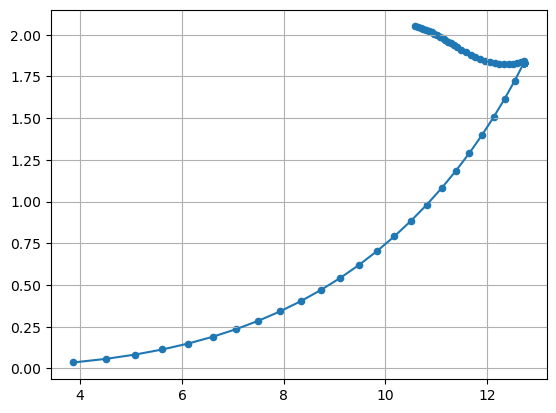

In [29]:
plt.scatter(radius,mass,s=20)
plt.plot(radius,mass)
plt.grid()

In [30]:
from TOV_Solver import generate_mr_curve

In [31]:
P_arr

array([  2.64505792,   2.76968205,   2.89894059,   3.03296071,
         3.17187188,   3.31580585,   3.46489668,   3.61928078,
         3.7790969 ,   3.94448615,   4.11559205,   4.29256052,
         4.4755399 ,   4.664681  ,   4.86013706,   5.06206386,
         5.27061963,   5.48596516,   5.70826376,   5.93768133,
         6.17438632,   6.41854982,   6.67034549,   6.92994967,
         7.19754135,   7.47330218,   7.75741652,   8.05007145,
         8.35145677,   8.66176504,   8.98119159,   9.30993455,
         9.64819486,   9.99617627,  10.3540854 ,  10.72213172,
        11.10052761,  11.48948833,  11.88923207,  12.29997997,
        12.72195614,  13.15538765,  13.60050457,  14.05754001,
        14.52673011,  15.00831404,  15.50253407,  16.00963558,
        16.52986702,  17.06347999,  17.61072927,  18.17187275,
        18.74717156,  19.33689002,  19.94129565,  20.56065926,
        21.19525488,  21.84535985,  22.5112548 ,  23.19322367,
        23.89155376,  24.6065357 ,  25.33846351,  26.08

In [32]:
E_arr

array([2.07080299e-10, 2.09060301e-10, 2.11041859e-10, 2.13025018e-10,
       2.15009820e-10, 2.16996309e-10, 2.18984532e-10, 2.20974533e-10,
       2.22966359e-10, 2.24960059e-10, 2.26955679e-10, 2.28953269e-10,
       2.30952878e-10, 2.32954558e-10, 2.34958361e-10, 2.36964337e-10,
       2.38972541e-10, 2.40983026e-10, 2.42995848e-10, 2.45011062e-10,
       2.47028724e-10, 2.49048893e-10, 2.51071627e-10, 2.53096984e-10,
       2.55125025e-10, 2.57155811e-10, 2.59189404e-10, 2.61225867e-10,
       2.63265263e-10, 2.65307658e-10, 2.67353116e-10, 2.69401705e-10,
       2.71453492e-10, 2.73508546e-10, 2.75566935e-10, 2.77628731e-10,
       2.79694005e-10, 2.81762828e-10, 2.83835275e-10, 2.85911419e-10,
       2.87991336e-10, 2.90075103e-10, 2.92162796e-10, 2.94254493e-10,
       2.96350275e-10, 2.98450222e-10, 3.00554414e-10, 3.02662935e-10,
       3.04775868e-10, 3.06893298e-10, 3.09015309e-10, 3.11141989e-10,
       3.13273426e-10, 3.15409707e-10, 3.17550924e-10, 3.19697168e-10,
      

In [33]:
radii, masses, compacts, love_nums = generate_mr_curve(e_arr, P_arr)

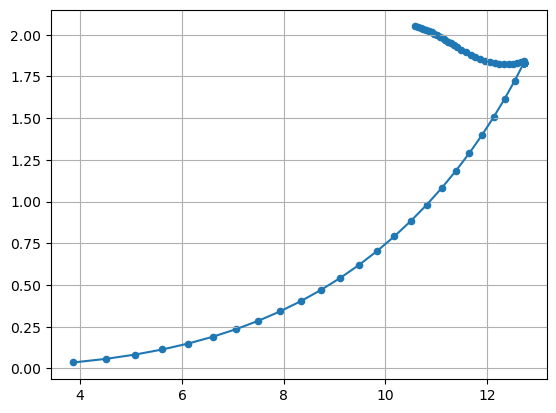

In [34]:
plt.scatter(radii,masses,s=20)
plt.plot(radius,mass)
plt.grid()

Part 2

In [161]:
n1_b = np.linspace(n_b[0], n_b[1], 20)
P1_b = P_from_nb(n1_b, K_b[0], Gam_b[0])
mu1_b = mu_from_nb(n1_b, K_b[0], Gam_b[0], m0[0])
e1_b = e_from_n(n1_b, K_b[0], Gam_b[0], m0[0])
#cs_1 = cs(mu1_b,K_b[0],Gam_b[0],n_b[0])

n2_b = np.linspace(n_b[1], n_b[2], 20)
P2_b = P_from_nb(n2_b, K_b[1], Gam_b[1])
mu2_b = mu_from_nb(n2_b, K_b[1], Gam_b[1], m0[1])
e2_b = e_from_n(n2_b, K_b[1], Gam_b[1], m0[1])
#cs_2 = cs(mu2_b,K_b[1],Gam_b[1],n_b[1])

n3_b = np.linspace(n_b[2], n_b[3], 20)
P3_b = P_from_nb(n3_b, K_b[2], Gam_b[2])
mu3_b = mu_from_nb(n3_b, K_b[2], Gam_b[2], m0[2])
e3_b = e_from_n(n3_b, K_b[2], Gam_b[2], m0[2])
#cs_3 = cs(mu3_b,K_b[2],Gam_b[2],n_b[2])

n4_b = np.linspace(n_b[3], n_b[4], 20)
P4_b = P_from_nb(n4_b, K_b[3], Gam_b[3])
mu4_b = mu_from_nb(n4_b, K_b[3], Gam_b[3], m0[3])
e4_b = e_from_n(n4_b, K_b[3], Gam_b[3], m0[3])
#cs_4 = cs(mu4_b,K_b[3],Gam_b[3],n_b[3])


P_arr = np.concatenate((P1_b[1:-1], P2_b[1:-1], P3_b[1:-1], P4_b[1:-1]))
e_arr = np.concatenate((e1_b[1:-1], e2_b[1:-1], e3_b[1:-1], e4_b[1:-1]))
n_arr = np.concatenate((n1_b[1:-1], n2_b[1:-1], n3_b[1:-1], n4_b[1:-1]))
mu_arr = np.concatenate((mu1_b[1:-1], mu2_b[1:-1], mu3_b[1:-1], mu4_b[1:-1]))
#cs_arr = np.concatenate((cs_1,cs_2,cs_3,cs_4))
cs2 = np.gradient(P_arr,e_arr)

In [163]:
len(mu_arr)

72

In [100]:
mu_hadronic=mu1_b[1:]
P_hadronic=P1_b[1:]

mu3_b=mu_from_nb(n3_b[:-1], K_b[2], Gam_b[2], m0[2])
mu4_b = mu_from_nb(n4_b[:-1], K_b[3], Gam_b[3], m0[3])
mu_quark_11 = np.concatenate((mu3_b,mu4_b))
P_quark_11= np.concatenate((P3_b[:-1],P4_b[:-1]))


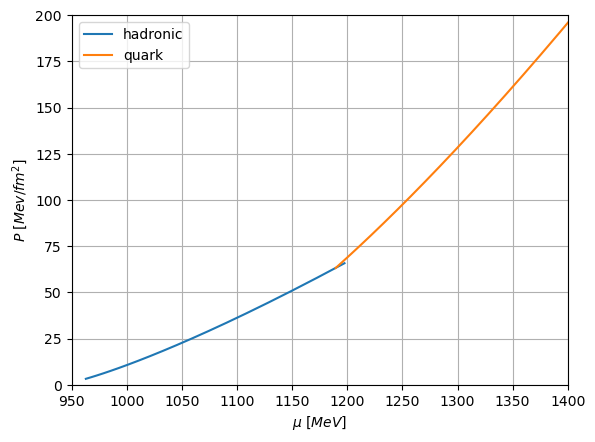

In [101]:
plt.plot(mu_hadronic, P_hadronic, label = "hadronic")
plt.plot(mu_quark_11, P_quark_11, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([950,1400])
plt.ylim([0,200])
plt.grid()

In [102]:
print(x_intersect)
print(y_intersect)

1189.859906604403
63.460782642527796


In [103]:
P_min = min(P_hadronic)
mu_min = min(mu_hadronic)

print(r"The minimum value of P                      : "+str(P_min)+" [Mev/fm^2] ")
print(r"The corresponding value of mu for minimum P : "+str(mu_min)+" [Mev] ")

The minimum value of P                      : 3.201751899985748 [Mev/fm^2] 
The corresponding value of mu for minimum P : 962.7660862286051 [Mev] 


In [104]:
mu_crit = x_intersect
P_crit_1 = y_intersect*(1+0.01)
P_crit_2 = y_intersect*(1+0.2)

In [105]:
P_crit=np.linspace(P_crit_1,P_crit_2,1000)

In [106]:
from scipy.optimize import minimize
import numpy as np

a = []
b = []
c = []
P_opt = []

for P in P_crit:
    # Define reference points
    x1, y1 = mu_min, P_min
    x2, y2 = mu_crit, P

    x_had = np.array(mu_hadronic[1:])
    y_had = np.array(P_hadronic[1:])

    x_quark = np.array(mu_quark_11[1:])
    y_quark = np.array(P_quark_11[1:])

    # Define the cubic function
    def cubic(x, a, b, c):
        return a * (x - x2)**3 + b * (x - x2)**2 + c * (x - x2) + y2

    # Objective function (no specific objective, only constraints)
    def objective(params):
        return 0

    # Initial guess for (a, b, c)
    initial_guess = [0, 0, 0]

    # Equality constraint: Pass through (x1, y1)
    def eq_constraint(params):
        a, b, c = params
        return cubic(x1, a, b, c) - y1

    # Inequality constraint: Must be above hadronic EoS
    def ineq_constraint_had(params):
        a, b, c = params
        return cubic(x_had, a, b, c) - y_had

    # Inequality constraint: Must be above quark EoS
    def ineq_constraint_quark(params):
        a, b, c = params
        return cubic(x_quark, a, b, c) - y_quark

    # Intersection constraint: Ensure it intersects quark EoS at least once
    def intersect_quark_constraint(params):
        a, b, c = params
        cubic_vals = cubic(x_quark, a, b, c)
        return np.max(y_quark - cubic_vals)

    # Define constraints
    constraints = [
        {'type': 'eq', 'fun': eq_constraint},
        {'type': 'ineq', 'fun': ineq_constraint_had},
        {'type': 'ineq', 'fun': ineq_constraint_quark},
        {'type': 'ineq', 'fun': intersect_quark_constraint}
    ]

    # Bounds for stability
    bounds = [(-10, 10), (-10, 10), (-10, 10)]

    # Perform the optimization
    result = minimize(objective, initial_guess, constraints=constraints, bounds=bounds)

    if result.success:
        a_opt, b_opt, c_opt = result.x
        a.append(a_opt)
        b.append(b_opt)
        c.append(c_opt)
        P_opt.append(P)
        print(f"For P_crit = {P}: a = {a_opt}, b = {b_opt}, c = {c_opt}")
    else:
        print(f"Optimization failed for P_crit = {P}")

For P_crit = 64.09539046895307: a = 1.5565906551325688e-05, b = 0.004234926837770928, c = 0.4271100470167586
For P_crit = 64.10746008727347: a = 1.525157409441702e-05, b = 0.004161186554416483, c = 0.426627861270355
For P_crit = 64.11952970559388: a = 1.4937242506762656e-05, b = 0.0040874464737989035, c = 0.4261456767446922
For P_crit = 64.13159932391427: a = 1.4622910784637972e-05, b = 0.004013706361698494, c = 0.4256634919857591
For P_crit = 64.14366894223467: a = 1.4308578443968476e-05, b = 0.003939966105885817, c = 0.42518130649928365
For P_crit = 64.15573856055508: a = 1.3994247057374094e-05, b = 0.003866226072018528, c = 0.42469912221205197
For P_crit = 64.16780817887548: a = 1.3831946157019276e-05, b = 0.0038296386598930267, c = 0.4248136128093386
For P_crit = 64.17987779719587: a = 1.3681722611806607e-05, b = 0.0037960027683167953, c = 0.4249755269558369
For P_crit = 64.19194741551628: a = 1.3531491916694292e-05, b = 0.003762365211369809, c = 0.425137431603047
For P_crit = 64.2

In [150]:
a =[]
b =[]
P_opt=[]
for P in P_crit:
    # Define your points
    x1, y1 = mu_min, P_min
    x2, y2 = mu_crit, P

    x_points = mu_quark_11
    y_points = P_quark_11

    # For inequality constraint defining hadronic part.
    x_values = np.array(mu_hadronic[1:])  # Hadronic Part x_values
    f_values = np.array(P_hadronic[1:])    # Corresponding y_values

    x_values_1 = np.array(mu_quark_11[1:])  
    f_values_1 = np.array(P_quark_11[1:])

    # Define the quadratic function
    def quadratic(x, a, b):
        return a * (x - x2)**2 + b * (x - x2) + y2

    # Objective function: sum of squared differences
    def objective(params):
        a, b = params
        return 0

    # Initial guess for parameters
    initial_guess = [0, 0]

    # Constraints to pass through (x1, y1)
    def eq_constraint(params):
        a, b = params
        return quadratic(x1, a, b) - y1

    def ineq_constraint(params):
        a, b = params
        return quadratic(x_values, a, b) - f_values
    def ineq_constraint_1(params):
        a, b = params
        return quadratic(x_values_1, a, b) - f_values_1
    

    # Define the constraint in the form required by 'minimize'
    constraints = [
        {'type': 'eq', 'fun': eq_constraint},
        {'type': 'ineq', 'fun': ineq_constraint},
        {'type': 'ineq', 'fun': ineq_constraint_1}
    ]
    # Perform the optimization
    result = minimize(objective, initial_guess, constraints=constraints)
    
    if result.success:
        a_opt, b_opt = result.x
        a.append(a_opt)
        b.append(b_opt)
        P_opt.append(P)
        print(f"For P_crit = {P}: Optimal parameters found: a = {a_opt}, b = {b_opt}")

For P_crit = 74.40221706944756: Optimal parameters found: a = 0.0006012827723434752, b = 0.4503581220500828
For P_crit = 74.41424172132758: Optimal parameters found: a = 0.0006010430581977859, b = 0.4503568051613567
For P_crit = 74.42626637320761: Optimal parameters found: a = 0.0006008033353850784, b = 0.45035548630752803
For P_crit = 74.43829102508764: Optimal parameters found: a = 0.0006005636212625494, b = 0.45035416942405304
For P_crit = 74.45031567696766: Optimal parameters found: a = 0.0006003239158069838, b = 0.4503528545056684
For P_crit = 74.46234032884769: Optimal parameters found: a = 0.0006000842016613101, b = 0.4503515376169459
For P_crit = 74.47436498072771: Optimal parameters found: a = 0.0005998444788487261, b = 0.45035021876314507
For P_crit = 74.48638963260774: Optimal parameters found: a = 0.0005996047647261769, b = 0.45034890187966564
For P_crit = 74.49841428448777: Optimal parameters found: a = 0.0005993650592704923, b = 0.45034758696125404
For P_crit = 74.5104389

NameError: name 'P_crit' is not defined

In [107]:
P_opt

[64.09539046895307,
 64.10746008727347,
 64.11952970559388,
 64.13159932391427,
 64.14366894223467,
 64.15573856055508,
 64.16780817887548,
 64.17987779719587,
 64.19194741551628,
 64.20401703383668,
 64.21608665215707,
 64.22815627047748,
 64.24022588879788,
 64.25229550711828,
 64.26436512543869,
 64.27643474375908,
 64.28850436207948,
 64.30057398039988,
 64.31264359872029,
 64.32471321704068,
 64.33678283536108,
 64.34885245368149,
 64.36092207200188,
 64.37299169032228,
 64.38506130864269,
 64.39713092696309,
 64.40920054528348,
 64.4212701636039,
 64.43333978192429,
 64.44540940024469,
 64.4574790185651,
 64.46954863688549,
 64.48161825520589,
 64.4936878735263,
 64.5057574918467,
 64.51782711016709,
 64.5298967284875,
 64.5419663468079,
 64.55403596512829,
 64.5661055834487,
 64.5781752017691,
 64.5902448200895,
 64.6023144384099,
 64.6143840567303,
 64.6264536750507,
 64.6385232933711,
 64.6505929116915,
 64.6626625300119,
 64.6747321483323,
 64.6868017666527,
 64.6988713849731

In [108]:
mu_quad = np.linspace(mu_min,1800,1000)
P_quad = a[-1] * (mu_quad - x2)**2 + b[-1] * (mu_quad - x2) + y2

In [109]:
mu_quad = np.linspace(mu_min,1800,1000)
P_quad = a[-1] * (mu_quad - x2)**3 + b[-1] * (mu_quad - x2)**2 + c[-1] * (mu_quad - x2) + y2

In [110]:
len(P_opt)

1000

In [111]:
delta_pmax=(P_opt-y_intersect)/y_intersect
delta_pmax

array([0.01      , 0.01019019, 0.01038038, 0.01057057, 0.01076076,
       0.01095095, 0.01114114, 0.01133133, 0.01152152, 0.01171171,
       0.0119019 , 0.01209209, 0.01228228, 0.01247247, 0.01266266,
       0.01285285, 0.01304304, 0.01323323, 0.01342342, 0.01361361,
       0.0138038 , 0.01399399, 0.01418418, 0.01437437, 0.01456456,
       0.01475475, 0.01494494, 0.01513514, 0.01532533, 0.01551552,
       0.01570571, 0.0158959 , 0.01608609, 0.01627628, 0.01646647,
       0.01665666, 0.01684685, 0.01703704, 0.01722723, 0.01741742,
       0.01760761, 0.0177978 , 0.01798799, 0.01817818, 0.01836837,
       0.01855856, 0.01874875, 0.01893894, 0.01912913, 0.01931932,
       0.01950951, 0.0196997 , 0.01988989, 0.02008008, 0.02027027,
       0.02046046, 0.02065065, 0.02084084, 0.02103103, 0.02122122,
       0.02141141, 0.0216016 , 0.02179179, 0.02198198, 0.02217217,
       0.02236236, 0.02255255, 0.02274274, 0.02293293, 0.02312312,
       0.02331331, 0.0235035 , 0.02369369, 0.02388388, 0.02407

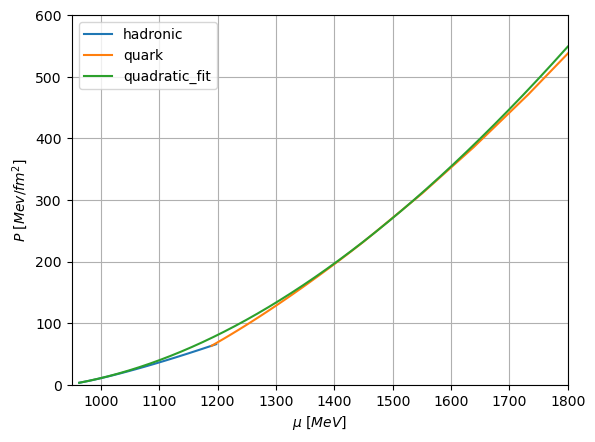

In [112]:
plt.plot(mu_hadronic, P_hadronic, label = "hadronic")
plt.plot(mu_quark_11, P_quark_11, label = "quark")
plt.plot(mu_quad,P_quad,label="quadratic_fit")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([950,1800])
plt.ylim([0,600])
plt.grid()

In [113]:
import numpy as np
from scipy import interpolate

# Given arrays
x1 = np.array(mu_quad)
y1 = np.array(P_quad)

x2 = np.array(mu_quark_11)
y2 = np.array(P_quark_11)

# Interpolate both curves
P_quad_int_func = interpolate.interp1d(x1, y1, kind='linear', fill_value="extrapolate")
P_quark_int_func = interpolate.interp1d(x2, y2, kind='linear', fill_value="extrapolate")

# Use a common range for both interpolations
mu_min = max(min(x1), min(x2))
mu_max = min(max(x1), max(x2))
mu_common = np.linspace(mu_min, mu_max, 1000)

# Evaluate the interpolated functions over the common mu range
P_quad_array = P_quad_int_func(mu_common)
P_quark_array = P_quark_int_func(mu_common)

# Compute the difference between the two curves
difference = P_quad_array - P_quark_array

# Find where the difference changes sign (intersection point)
sign_changes = np.where(np.diff(np.sign(difference)))[0]

if sign_changes.size > 0:
    intersection_index = sign_changes[0]  # Take the first intersection found
    mu_intersection = mu_common[intersection_index]
    P_intersection = P_quad_array[intersection_index]

    print(f"Intersection point: mu = {mu_intersection}, P = {P_intersection}")

    # Find the closest index in the original mu_quad array
    original_index_quad = np.argmin(np.abs(x1 - mu_intersection))
    original_index_quark = np.argmin(np.abs(x2 - mu_intersection))

    print(f"Closest index in original mu_quad array: {original_index_quad}")
    print(f"Closest index in original mu_quark array: {original_index_quark}")

else:
    print("No intersection found within the given range.")

Intersection point: mu = 1466.273628249992, P = 244.66958253526633
Closest index in original mu_quad array: 601
Closest index in original mu_quark array: 19


In [116]:
x1 = np.array(mu_quad)
y1 = np.array(P_quad)

x2 = np.array(mu_quark_11)
y2 = np.array(P_quark_11)

P_quad_int_func = interpolate.interp1d(x1, y1, fill_value='extrapolate')
P_quark_int_func = interpolate.interp1d(x2, y2)

mu_new_1 = np.linspace(min(mu_quark_11), max(mu_quark_11), 1000)
P_quad_array = P_quad_int_func(mu_new_1)
P_quark_array = P_quark_int_func(mu_new_1)

# Calculate the difference and find the intersection
y_diff = np.abs(P_quad_array - P_quark_array)
index_intersect_1 = np.argmin(y_diff)
mu_intersection = mu_new_1[index_intersect_1]
P_intersection = P_quad_array[index_intersect_1]


orginal_index_quad = np.argmin(np.abs(x1 - mu_intersection))


In [117]:
mu_quad_11 = mu_quad[:orginal_index_quad-1]
P_quad_11 = P_quad[:orginal_index_quad-1]

In [118]:
n_quad_11 = np.gradient(P_quad_11, mu_quad_11)
e_quad_11 = (n_quad_11*mu_quad_11)-P_quad_11

In [164]:
for i in range(len(P_arr)):
    if P_quad_11 [-1] > P_arr[i]:
         print(i)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53


In [160]:
len(P_arr)

54

In [165]:
P_quad_12 = np.concatenate((P_quad_11, P_arr[53:]))
mu_quad_12 = np.concatenate((mu_quad_11, mu_arr[53:]))
n_quad_12 = np.gradient(P_quad_12, mu_quad_12)
e_quad_12 = (n_quad_12*mu_quad_12)-P_quad_12

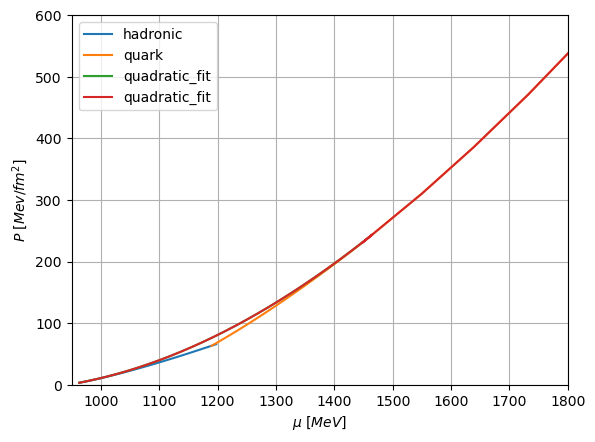

In [166]:
plt.plot(mu_hadronic, P_hadronic, label = "hadronic")
plt.plot(mu_quark_11, P_quark_11, label = "quark")
plt.plot(mu_quad_11,P_quad_11,label="quadratic_fit")
plt.plot(mu_quad_12,P_quad_12,label="quadratic_fit")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.xlim([950,1800])
plt.ylim([0,600])
plt.grid()

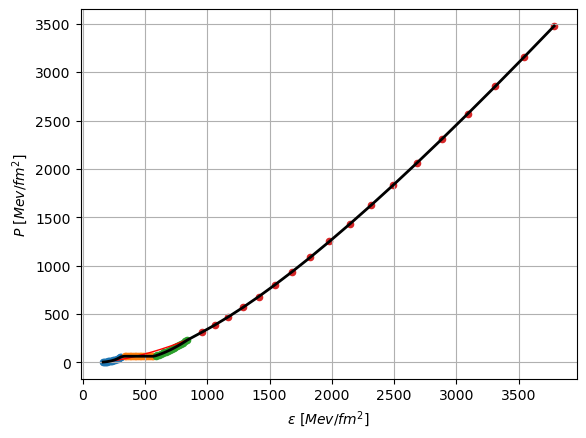

In [120]:
plt.scatter(e1_b[1:-1], P1_b[1:-1],s=20);
plt.scatter(e2_b[1:-1], P2_b[1:-1],s=20);
plt.scatter(e3_b[1:-1], P3_b[1:-1],s=20);
plt.scatter(e4_b[1:-1], P4_b[1:-1],s=20);

plt.plot(e_quad_11,P_quad_11, linewidth = 1,color="red")

plt.plot(e_arr, P_arr, linewidth = 2, color = "black");
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

In [121]:
cs2_11 = np.gradient(P_quad_11,e_quad_11)

In [122]:
P_arr_12 = np.concatenate((P1_b[:-1], P2_b[1:-1], P3_b[1:-1], P4_b[1:-1]))
e_arr_12 = np.concatenate((e1_b[:-1], e2_b[1:-1], e3_b[1:-1], e4_b[1:-1]))
n_arr_12 = np.concatenate((n1_b[:-1], n2_b[1:-1], n3_b[1:-1], n4_b[1:-1]))
mu_arr_12 = np.concatenate((mu1_b[:-1], mu2_b[1:-1], mu3_b[1:-1], mu4_b[1:-1]))
cs2_12 = np.gradient(P_arr_12,e_arr_12)

In [123]:
len(mu_arr_12)

71

In [124]:
len(cs2_12)

73

ValueError: x and y must be the same size

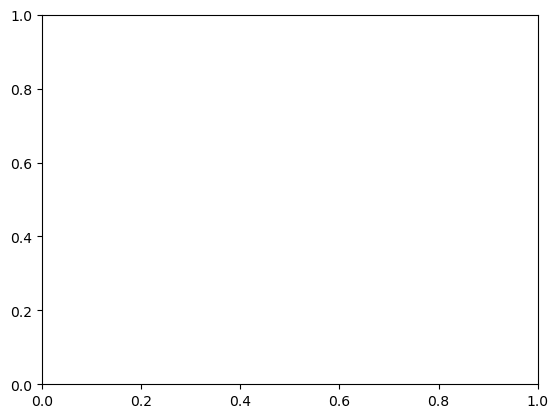

In [125]:
plt.scatter(mu_arr_12,cs2_12,alpha=0.2);
plt.plot(mu_arr_12,cs2_12)
plt.plot(mu_quad_11[2:-1],cs2_11[2:-1])
plt.grid()
plt.xlabel(r"$\mu \ [Mev]$")
plt.ylabel(r"$C_s^2$")
plt.show();


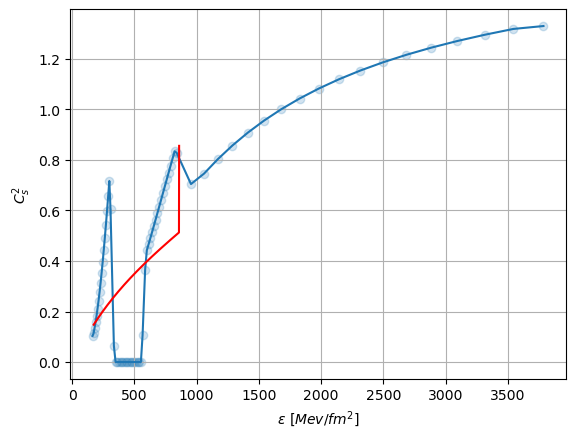

In [126]:
plt.scatter(e_arr,cs2,alpha=0.2);
plt.plot(e_arr,cs2)
plt.plot(e_quad_11[2:-1],cs2_11[2:-1],color="red")
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$C_s^2$")
plt.show();

In [127]:
# MASS RELATION

In [128]:
P_arr = np.concatenate((P1_b[1:-1], P3_b[1:-1], P4_b[1:-1]))
mu_arr = np.concatenate((mu1_b[1:-1], mu3_b[1:-1], mu4_b[1:-1]))
e_arr = np.concatenate((e1_b[1:-1], e3_b[1:-1], e4_b[1:-1]))

In [129]:
def find_index(arr, value):
    count = 0
    for i in range(len(arr)):
        if arr[i] < value:
            count = count+1
        else :
            return count

In [130]:
len(P_arr)

54

In [131]:
mu_c_h_arr

[1165.6037358238825, 1135.3435623749167, 1084.6697798532355, 1066.177451634423]

In [132]:
mu_c_q_arr

[1215.3168779186124, 1253.022014676451, 1319.7865243495664, 1348.1254169446297]

In [133]:
mu_arr

array([ 962.76608623,  967.35686014,  972.59230587,  978.52927856,
        985.22693366,  992.74671922, 1001.15236865, 1010.50989363,
       1020.88757744, 1032.35596847, 1044.98787398, 1058.85835414,
       1074.04471621, 1090.62650895, 1108.68551725, 1128.30575683,
       1149.57346925, 1172.57711692, 1199.64322873, 1210.33103276,
       1221.46322311, 1233.04885141, 1245.09696928, 1257.61662835,
       1270.61688026, 1284.10677664, 1298.09536911, 1312.5917093 ,
       1327.60484885, 1343.14383937, 1359.21773252, 1375.8355799 ,
       1393.00643316, 1410.73934392, 1429.04336381, 1549.77321088,
       1638.34987359, 1732.37886976, 1831.78219641, 1936.48810576,
       2046.43024235, 2161.54694333, 2281.78066346, 2407.0774973 ,
       2537.38677803, 2672.66073755, 2812.85421615, 2957.92441264,
       3107.83066783, 3262.53427583, 3421.99831857, 3586.18751996])

In [134]:
P_arr_dp = []
E_arr_dp = []
number_density = []

for i in range(len(A)):
    mu_new = mu_arr
    index_1 = find_index(mu_new, mu_c_h_arr[i])
    index_2 = find_index(mu_new, mu_c_q_arr[i])
    print(index_1)
    print(index_2)

    P_m = quad_P(x_intersect, mu_new[index_1:index_2], A[i], B[i], delta_P_arr[i], y_intersect)
    P_had_half = P_arr[:index_1]
    P_quark_half = P_arr[index_2:]

    grad_had = np.gradient(P_had_half,mu_new[:index_1])
    grad_m = np.gradient(P_m,mu_new[index_1:index_2])
    grad_quark = np.gradient(P_quark_half,mu_new[index_2:])


    grad_dummy = np.concatenate((grad_had[:-1],grad_m[:-1],grad_quark))
    P_arr_dummy = np.concatenate((P_had_half[:-1],P_m[:-1],P_quark_half))

    e_dummy = (grad_dummy*mu_new[:-2])-P_arr_dummy

    P_arr_dp.append(P_arr_dummy)
    E_arr_dp.append(e_dummy)
    number_density.append(grad_dummy)

17
20


ValueError: when 1d, distances must match the length of the corresponding dimension

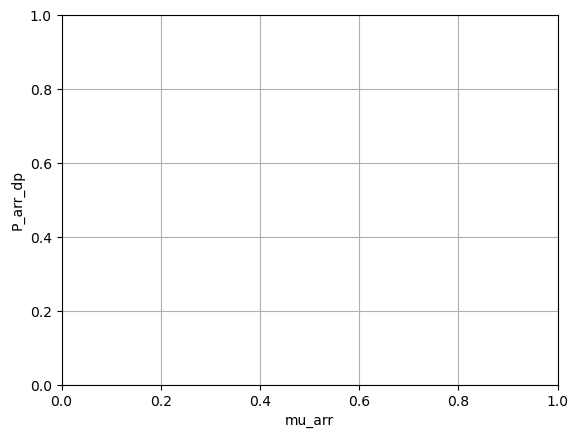

In [135]:
for i in range(len(P_arr_dp)):
    plt.scatter(mu_new[:-2],P_arr_dp[i])
plt.ylabel('P_arr_dp')
plt.xlabel('mu_arr')
plt.grid(True)
plt.show()

In [138]:
plt.scatter(E_arr_dp[0],P_arr_dp[0])
plt.ylabel('P_arr_dp')
plt.xlabel('mu_arr')
plt.grid(True)
plt.show()

IndexError: list index out of range

In [139]:
from TOV_Solver import generate_mr_curve

In [81]:
r, m, c, l = [], [], [], []

In [82]:
radii, masses, compacts, love_nums = [0]*len(P_arr_dp), [0]*len(P_arr_dp), [0]*len(P_arr_dp), [0]*len(P_arr_dp)

In [83]:
for i in range(len(P_arr_dp)):
    radii[i], masses[i], compacts[i], love_nums[i] = generate_mr_curve(E_arr_dp[i], P_arr_dp[i])

In [140]:
plt.plot(radii[2],masses[2])
plt.plot(radii[1],masses[1])
plt.xlim(10,13)
plt.ylim(1.50,3.00)

NameError: name 'radii' is not defined

In [162]:
check_twins(masses[1])

True


In [178]:
len(radii_11)

80

In [167]:
radius, mass,c,l = generate_mr_curve(e_quad_12, P_quad_12)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


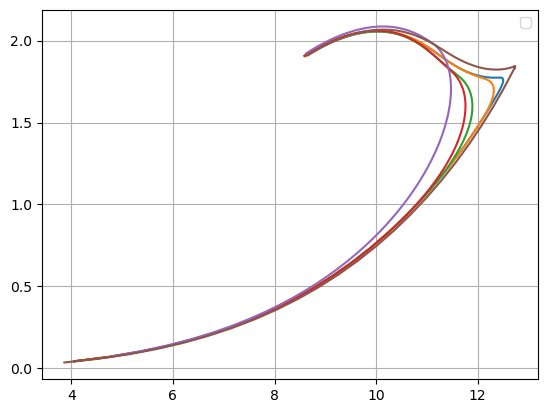

In [172]:
for i in range(len(r)):
    plt.plot(m[i],r[i])
plt.plot(radius,mass)
plt.plot(m12,r12)
plt.grid()
plt.legend()

In [ ]:
def check_twins(mass):
    for i in range(len(mass)-2):
        if mass[i+1]-mass[i] < 0 and mass[i+2]-mass[i+1] > 0:
            return print('True')
    else:
        return print('False')

In [86]:
for i in range(len(masses)):
    check_twins(masses[i])

True
True
False
False
False
False
False
False


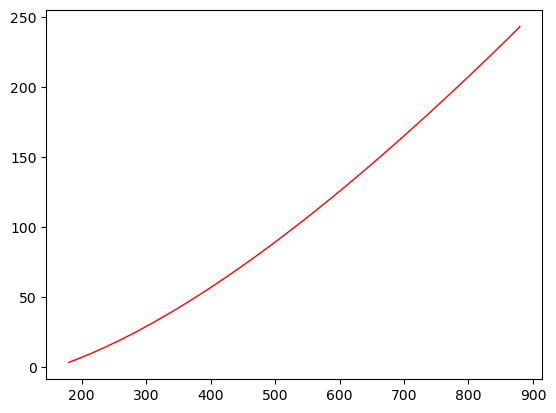

In [87]:
plt.plot(e_quad_11,P_quad_11, linewidth = 1,color="red")

In [2]:
import numpy as np

In [3]:
k = np.linspace(2.5, 3.5, 100)

In [4]:
k[40]

2.904040404040404

In [ ]:
plt.plot(e_quad_11,P_quad_11, linewidth = 1,color="red")

plt.plot(e_arr, P_arr, linewidth = 2, color = "black");

In [91]:
katta = find_index(e_arr,e_quad_11[-1])

In [93]:
e_hehe=np.concatenate((e_quad_11,e_arr[katta:-1]))
p_hehe=np.concatenate((P_quad_11,P_arr[katta:-1]))

In [94]:
radii_11, masses_11, compacts_11, love_nums_11 = generate_mr_curve(e_hehe,p_hehe)